# Ноутбук 1. Математический и вычислительный инструментарий асимметричной криптографии

## Интенсивная актуализация предварительных знаний для магистерского курса

Этот ноутбук **не является вводным курсом элементарной теории чисел**. Предполагается, что студент уже изучал делимость, сравнения, НОД и алгоритм Евклида в бакалавриате, а также владеет базовыми методами математического доказательства. 

Здесь мы собираем именно тот математический и вычислительный инструментарий, который далее будет без повторного объяснения использоваться в RSA, Диффи—Хеллмане, Эль-Гамале, конечных полях и криптографии на эллиптических кривых.

К концу ноутбука должны быть доступны операции

$$
a^{-1}\pmod n,\qquad a^e\pmod n,\qquad \operatorname{CRT}(\ldots),
$$

а также проверенные реализации `gcd`, `extended_gcd`, `solve_linear_diophantine`, `mod_inverse`, `solve_linear`, `mod_pow`, `crt`, `garner_crt`.

Для ключевых результатов используем сквозную схему:

$$
\boxed{
\text{математический результат}
\to
\text{конструкция}
\to
\text{алгоритм}
\to
\text{корректность}
\to
\text{сложность}
\to
\text{криптографическое применение}.
}
$$

В вычислительных блоках отдельно различаем **доказательство корректности**, **тестирование реализации** и **эксперимент**: доказательство устанавливает свойство для всех допустимых входов; тесты помогают обнаруживать ошибки конкретного кода; эксперимент позволяет увидеть закономерность и сформулировать гипотезу. Даже большое число успешных тестов не заменяет доказательство корректности.


<div style="background-color: #342d43; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #7653a6;">

### 🧩 Цель актуализации предварительных знаний

Собрать компактный арифметический инструментарий:

```text
crypto_math/
└── number_theory.py
    ├── divides()
    ├── gcd()
    ├── extended_gcd()
    ├── solve_linear_diophantine()
    ├── mod_inverse()
    ├── solve_linear()
    ├── mod_pow()
    ├── crt()
    └── garner_crt()
```

Для каждой основной операции нас интересуют:

- **контракт**: допустимые входы и математическое постусловие;
- **инвариант или конструктивная теорема**, обеспечивающие корректность;
- **стоимость вычисления**, измеряемая относительно размера входа;
- **проверка свойств** на случайных данных;
- место операции в последующих криптографических конструкциях.

</div>


### Терминологическое соглашение

Основной язык курса — русский. Для понятий, имеющих устойчивый русский академический эквивалент, используется русский термин. При **первом содержательном упоминании** рядом в скобках приводится распространённый английский термин — это облегчает поиск англоязычных учебников, статей, стандартов и документации.

Например:

- **сравнение по модулю** (*congruence modulo*);
- **наибольший общий делитель, НОД** (*greatest common divisor, GCD*);
- **расширенный алгоритм Евклида** (*extended Euclidean algorithm*);
- **обратный элемент по модулю** (*modular multiplicative inverse*);
- **быстрое модульное возведение в степень** (*fast modular exponentiation*);
- **китайская теорема об остатках, КТО** (*Chinese Remainder Theorem, CRT*);
- **инвариант цикла** (*loop invariant*);
- **битовая длина** (*bit length*);
- **сложность по битовым операциям** (*bit complexity*).

Имена функций Python (`gcd`, `extended_gcd`, `mod_inverse`, `mod_pow`, `crt`) не переводятся: это элементы программного интерфейса, а не терминология математического текста.


## 1.1. Криптографическая карта вычислений

В следующих разделах курса нам понадобятся:

- Диффи—Хеллман и Эль-Гамаль: $g^x\bmod p$;
- RSA: $m^e\bmod n$, обратимые элементы и реконструкция по КТО;
- конечные поля: деление как умножение на обратный элемент;
- криптография на эллиптических кривых: аналогичная идея быстрого умножения скаляра, но уже в группе точек.

Поэтому основной вопрос здесь не «что такое остаток?», а:

> какие арифметические операции должны быть математически корректны и вычислительно пригодны для чисел длиной 256–4096 бит?

Эта постановка требует различать числовую величину входа и **размер его представления**. Для целых чисел размер входа естественно измеряется битовой длиной.


## 1.2. Сравнения и арифметика классов вычетов — краткое повторение

Фиксируем обозначения, которые далее используются без пояснений.

### Определение 1.1. Делимость

Пусть $a,b\in\mathbb Z$. Говорят, что $a$ **делит** $b$ (пишут $a\mid b$), если существует $k\in\mathbb Z$ такое, что $b=ak$; иначе пишут $a\nmid b$. Число $a$ называется **делителем** (*divisor*) числа $b$, а $b$ — **кратным** (*multiple*) числа $a$.

Отметим крайний случай, важный для программного контракта: $0\mid b$ тогда и только тогда, когда $b=0$.

### Определение 1.2. Сравнение по модулю

Пусть $n\ge 2$ и $a,b\in\mathbb Z$. Числа $a$ и $b$ **сравнимы по модулю $n$** (*congruent modulo $n$*), если $n\mid(a-b)$:

$$
a\equiv b\pmod n.
\tag{1.1}
$$

Эквивалентно, существует $q\in\mathbb Z$ такое, что

$$
a=b+qn,
\tag{1.2}
$$

то есть $a$ и $b$ дают одинаковый остаток при делении на $n$. Сравнимость по модулю $n$ — отношение эквивалентности на $\mathbb Z$.

### Определение 1.3. Класс вычетов

**Классом вычетов числа $a$ по модулю $n$** (*residue class modulo $n$*) называется множество

$$
[a]_n=\{\,b\in\mathbb Z:\ b\equiv a\pmod n\,\}
\tag{1.3}
$$

$$
=a+n\mathbb Z=\{\,a+kn:\ k\in\mathbb Z\,\}.
\tag{1.4}
$$

Например, $[2]_5=\{\ldots,-8,-3,2,7,12,\ldots\}$, поэтому

$$
[2]_5=[7]_5=[-3]_5.
\tag{1.5}
$$

Вообще,

$$
[a]_n=[b]_n\iff a\equiv b\pmod n.
\tag{1.6}
$$

Множество классов вычетов обозначается

$$
\mathbb Z/n\mathbb Z
\tag{1.7}
$$

и состоит ровно из $n$ классов:

$$
\mathbb Z/n\mathbb Z=\{[0]_n,[1]_n,\ldots,[n-1]_n\}.
\tag{1.8}
$$

Число из $\{0,1,\ldots,n-1\}$, лежащее в классе, называется **наименьшим неотрицательным представителем** (*least nonnegative representative*); в Python при $n>0$ его даёт выражение `a % n`.

Полезно различать три уровня: целое число $a\in\mathbb Z$, класс $[a]_n\in\mathbb Z/n\mathbb Z$ и выбранный представитель класса (например, `a % n`). В коде эти уровни обычно отождествляют, в доказательствах — нет.

### Арифметика классов вычетов

Операции определяются через представителей:

$$
[a]_n+[b]_n=[a+b]_n,
\tag{1.9}
$$

$$
[a]_n[b]_n=[ab]_n.
\tag{1.10}
$$

Определение корректно (*well-defined*), то есть не зависит от выбора представителей: если $a\equiv a'$ и $b\equiv b'\pmod n$, то

$$
a+b\equiv a'+b'\pmod n,
\tag{1.11}
$$

$$
ab\equiv a'b'\pmod n.
\tag{1.12}
$$

Именно свойства (1.11)–(1.12) позволяют заменять большие целые их представителями по модулю $n$ **до** выполнения дальнейших сложений и умножений.


In [1]:
def divides(a: int, b: int) -> bool:
    """Контракт: возвращает True тогда и только тогда, когда a | b (Определение 1.1).

    Крайний случай: 0 | b  <=>  b == 0.
    """
    if a == 0:
        return b == 0
    return b % a == 0


assert divides(3, 12) and divides(-3, 12) and divides(3, -12)
assert not divides(5, 12)
assert divides(7, 0)                        # любое число делит 0
assert divides(0, 0) and not divides(0, 5)  # 0 делит только 0
# Связь с Определением 1.2: a ≡ b (mod n)  <=>  n | (a - b)
assert divides(12, 17 - 5)


<div style="background-color: #243a30; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Пример 1.1. Редукция во время вычисления

Чтобы вычислить

$$
123456789^{10^6}\pmod{1009},
$$

не нужно строить само число $123456789^{10^6}$: в нём около 8 миллионов десятичных цифр. Благодаря совместимости сравнения с умножением, формула (1.12), редукцию можно выполнять после **каждого** умножения, и все промежуточные значения остаются меньше $1009$. Сначала можно заменить и само основание его представителем: $123456789\equiv 594\pmod{1009}$. Итог: $123456789^{10^6}\equiv 628\pmod{1009}$.

Эта идея — фундамент всех дальнейших вычислений: в §1.6 она вместе с двоичной записью показателя даст быстрое модульное возведение в степень.

</div>

<div style="background-color: #243a30; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Пример 1.2. Как получить целое число ровно из 512 бит

Для криптографических экспериментов важно контролировать не только верхнюю границу числа, но и его **битовую длину**.

Для положительного целого $n$ битовая длина равна

$$
\ell(n)=\lfloor\log_2 n\rfloor+1.
$$

Эквивалентно,

$$
2^{\ell(n)-1}\le n<2^{\ell(n)}.
$$

В Python значение $\ell(n)$ возвращает метод `n.bit_length()`.

Для генерации случайных значений используем модуль `secrets`:

```python
import secrets

n = secrets.randbits(512)

# Гарантируем, что число действительно 512-битное:
n |= (1 << 511)

print(n.bit_length())
```

Последняя строка гарантированно выведет

```text
512
```

Одного вызова `secrets.randbits(512)` недостаточно: он возвращает случайное целое в диапазоне

$$
0\le n<2^{512},
$$

поэтому старшие биты случайно могут оказаться нулевыми.

Операция

```python
n |= (1 << 511)
```

устанавливает старший бит в `1`, поэтому

$$
2^{511}\le n<2^{512}.
$$

#### Размер входа и сложность

В криптографии сложность алгоритма оценивают относительно **размера представления входа**, а не только относительно числовой величины входного числа. Обозначим через $L=\ell(n)$ битовую длину числа $n$ (см. формулу выше). Тогда $2^{L-1}\le n<2^L$, то есть $n$ имеет порядок $2^L$. Поэтому алгоритм, выполняющий $O(n)$ шагов, требует порядка

$$
O(2^L)
$$

шагов относительно битовой длины входа.

В этом ноутбуке будем различать два уровня оценки:

- **арифметическая сложность** — число делений, умножений или других операций над целыми числами;
- **сложность по битовым операциям** — учитывает, что одна операция над длинными числами сама имеет ненулевую стоимость.

Например, если $M(L)$ обозначает стоимость умножения двух $L$-битных чисел, то фраза «$O(L)$ умножений» ещё не означает $O(L)$ битовых операций.

На этом этапе нам достаточно уметь чётко различать эти два уровня. Более точные оценки появятся там, где они влияют на выбор криптографических параметров.

</div>


<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Практика. Не вычисляйте больше, чем нужно

1. Предскажите, совпадут ли два результата ниже.
2. Сгенерируйте несколько пар **ровно 512-битных** целых `a, b`, используя приём из примера 1.2, и проверьте предсказание.
3. Объясните совпадение через формулы (1.11)–(1.12), а не через особенности Python.
4. Сформулируйте, почему ранняя редукция критична при вычислении больших степеней.

</div>

In [2]:
import secrets

def random_exact_bits(bits: int) -> int:
    """Возвращает положительное целое ровно заданной битовой длины."""
    if bits < 1:
        raise ValueError("bits должно быть положительным")

    n = secrets.randbits(bits)
    n |= 1 << (bits - 1)
    return n


# Пример: две случайные величины ровно по 512 бит.
a = random_exact_bits(512)
b = random_exact_bits(512)

assert a.bit_length() == 512
assert b.bit_length() == 512

print("a.bit_length() =", a.bit_length())
print("b.bit_length() =", b.bit_length())

# Выберите модуль n > 0 и сравните:
# ((a % n) * (b % n)) % n
# (a * b) % n


n = secrets.randbits(512) | (1 << 511)

# Способ 1
result1 = ((a % n) * (b % n)) % n

# Способ 2
result2 = (a * b) % n

print("result1 =", result1)
print("result2 =", result2)
print("Результаты совпадают:", result1 == result2)

assert result1 == result2

for _ in range(10):
    a, b, n = (random_exact_bits(512) for _ in range(3))
    assert a.bit_length() == b.bit_length() == n.bit_length() == 512
    assert ((a % n) * (b % n)) % n == (a * b) % n
print('Проверены ещё 10 пар ровно по 512 бит.')

a.bit_length() = 512
b.bit_length() = 512
result1 = 10086817797538185356676542548884835646988222354414169040585685280894456184077437713363517252904630085571655712863334756549257343584626565753046089801289216
result2 = 10086817797538185356676542548884835646988222354414169040585685280894456184077437713363517252904630085571655712863334756549257343584626565753046089801289216
Результаты совпадают: True
Проверены ещё 10 пар ровно по 512 бит.


**Ответ.** Результаты совпадают: если $a=qn+r$, $b=sn+t$, то $ab= n(qsn+qt+sr)+rt$, поэтому $ab\equiv rt\pmod n$. Это совместимость сравнений с умножением. При ранней редукции сохранённые значения имеют не более битовой длины модуля, а произведения — примерно удвоенную длину; без неё длина $a^e$ растёт как $e\log_2 a$, что делает большие степени непрактичными.

### Определение 1.4. Полная система вычетов

Набор из $n$ целых чисел $r_0,r_1,\ldots,r_{n-1}$ называется **полной системой вычетов по модулю $n$** (*complete residue system modulo $n$*), если каждое целое число сравнимо по модулю $n$ ровно с одним из этих чисел.

Эквивалентно, классы $[r_0]_n,\ldots,[r_{n-1}]_n$ попарно различны и исчерпывают $\mathbb Z/n\mathbb Z$.

Стандартный пример — $0,1,\ldots,n-1$, но представители могут быть любыми, в том числе отрицательными.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.1. Полная система вычетов

Образуют ли числа
$$-16,\ 17,\ -6,\ 27,\ -20,\ 13,\ -2,\ 23$$
полную систему вычетов по модулю $8$?

Проверьте ответ вручную, приведя числа к наименьшим неотрицательным представителям, а затем программно с помощью `%`.

</div>

In [3]:
values = [-16, 17, -6, 27, -20, 13, -2, 23]
residues = [a % 8 for a in values]
print(residues)
assert residues == list(range(8))
print('Да, это полная система вычетов по модулю 8.')

[0, 1, 2, 3, 4, 5, 6, 7]
Да, это полная система вычетов по модулю 8.


**Ответ 1.1.** Вручную: $-16=-2\cdot8+0$, $17=2\cdot8+1$, $-6=-8+2$, $27=3\cdot8+3$, $-20=-3\cdot8+4$, $13=8+5$, $-2=-8+6$, $23=2\cdot8+7$. Получены все остатки от 0 до 7 ровно по одному разу, поэтому система полная.

## 1.3. НОД и алгоритм Евклида — повторение через инвариант

### Определение 1.5. Наибольший общий делитель

Пусть $a,b\in\mathbb Z$, причём $a$ и $b$ не равны нулю одновременно. **Наибольшим общим делителем** (*greatest common divisor, GCD*) чисел $a,b$ называется положительное целое число $d=\gcd(a,b)$, такое что
$$d\mid a,\qquad d\mid b,$$
и любой общий делитель $c$ чисел $a,b$ делит $d$:
$$c\mid a,\ c\mid b\Longrightarrow c\mid d.$$

Используем соглашения $\gcd(a,b)\ge0$ и $\gcd(a,0)=|a|$.

### Определение 1.6. Взаимно простые числа

Числа $a,b$ называются **взаимно простыми** (*coprime, relatively prime*), если
$$\gcd(a,b)=1.$$

Ключевой инвариант алгоритма Евклида:
$$\gcd(a,b)=\gcd(b,a\bmod b),\qquad b\ne0. \tag{1.13}$$

```python
def gcd(a: int, b: int) -> int:
    if a == 0 and b == 0:
        raise ValueError("gcd(0, 0) is undefined by the course convention")
    a, b = abs(a), abs(b)
    while b != 0:
        a, b = b, a % b
    return a
```

### Паспорт алгоритма `gcd`

**Контракт.** Вход: $a,b\in\mathbb Z$, не равные нулю одновременно. Выход: положительное число $d$, для которого

$$
d=\gcd(a,b).
$$

**Корректность.** На каждом шаге сохраняется НОД пары благодаря (1.13). Когда второй компонент становится равным нулю, первый компонент равен НОД исходной пары.

**Стоимость.** Число итераций алгоритма Евклида растёт как $O(\log\min(|a|,|b|))$ в арифметической модели. Ниже теорема Ламе даст строгую оценку и покажет, почему соседние числа Фибоначчи реализуют худший случай. Для криптографических входов важно, что логарифмический рост относительно числовой величины означает линейный рост по порядку битовой длины.

**Проверка реализации.** Для независимой перекрёстной проверки используйте `math.gcd` на допустимых входах.

In [4]:
def gcd(a: int, b: int) -> int:
    if a == 0 and b == 0:
        raise ValueError("gcd(0, 0) is undefined by the course convention")

    a, b = abs(a), abs(b)
    while b:
        a, b = b, a % b
    return a

assert gcd(252, 105) == 21
assert gcd(-30, 42) == 6

try:
    gcd(0, 0)
except ValueError:
    pass
else:
    raise AssertionError("gcd(0, 0) must be rejected by the course convention")


<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование 1.1. Алгоритм Евклида: инвариант и масштаб

1. Докажите (1.13) через множества общих делителей.
2. Укажите строку программы, реализующую переход (1.13).
3. Модифицируйте `gcd`, чтобы функция возвращала также количество итераций. Назовите её `gcd_with_iterations`. Проверка:
   ```python
   d, n = gcd_with_iterations(1312331323, 58123123)
   print(f"d={d}, количество итераций={n}")
   ```
   Ожидаемый результат: `d=1, количество итераций=21`. Объясните, что считается одной итерацией.
4. Для битовых длин $32,64,128,256,512,1024$ сгенерируйте несколько случайных пар и сравните среднее число итераций.
5. Сопоставьте наблюдаемое число шагов с битовой длиной входа. Почему рост не похож на полный перебор до $\min(|a|,|b|)$?
6. Дополнительно исследуйте пары соседних чисел Фибоначчи $(F_{k+1},F_k)$. Для нескольких $k$ измерьте число итераций, сравните его с $k-1$ и сформулируйте гипотезу о худшем случае. В следующем блоке эта гипотеза будет превращена в строгую теорему.

**Что является доказательством, а что экспериментом?** Пункт 1 доказывает корректность одного шага алгоритма для всех допустимых входов. Пункты 4–6 дают экспериментальные данные о числе шагов и позволяют сформулировать гипотезу, но сами по себе не доказывают ни асимптотическую оценку, ни утверждение о худшем случае.

</div>


In [5]:
def gcd_with_iterations(a, b):
    if a == b == 0:
        raise ValueError('Нулевая пара не допускается')
    a, b = abs(a), abs(b)
    steps = 0
    while b:
        a, b = b, a % b
        steps += 1
    return a, steps

assert gcd_with_iterations(1312331323, 58123123) == (1, 21)
print('Контрольная пара:', gcd_with_iterations(1312331323, 58123123))
for L in (32, 64, 128, 256, 512, 1024):
    counts = [gcd_with_iterations(random_exact_bits(L), random_exact_bits(L))[1] for _ in range(100)]
    print(L, 'бит: среднее число делений', sum(counts)/len(counts))

def fib(k):
    a, b = 0, 1
    for _ in range(k):
        a, b = b, a+b
    return a

for k in (3, 5, 10, 20, 100, 1000):
    d, steps = gcd_with_iterations(fib(k+1), fib(k))
    assert d == 1 and steps == k-1
    print('Фибоначчи: k =', k, 'делений =', steps)

Контрольная пара: (1, 21)
32 бит: среднее число делений 19.17
64 бит: среднее число делений 37.9
128 бит: среднее число делений 74.96
256 бит: среднее число делений 149.87
512 бит: среднее число делений 300.95
1024 бит: среднее число делений 596.08
Фибоначчи: k = 3 делений = 2
Фибоначчи: k = 5 делений = 4
Фибоначчи: k = 10 делений = 9
Фибоначчи: k = 20 делений = 19
Фибоначчи: k = 100 делений = 99
Фибоначчи: k = 1000 делений = 999


**Доказательство и интерпретация.** При $a=qb+r$ любой общий делитель $a,b$ делит $r=a-qb$; любой общий делитель $b,r$ делит $a=qb+r$. Значит, множества общих делителей совпадают и $\gcd(a,b)=\gcd(b,r)$. Переход реализует строка `a, b = b, a % b`. Одна итерация — одно деление с остатком, включая последнее с нулевым остатком. Для случайных входов число делений растёт примерно линейно по битовой длине, а не как величина числа. Для соседних чисел Фибоначчи при $k\ge2$ получается $k-1$ делений: почти все частные равны 1, остатки убывают медленнее всего. Эксперимент согласуется с теоремой Ламе, но не заменяет её доказательства.

In [6]:
# Для библиотечной gcd сохраняем исходную реализацию без печати.
assert gcd(252, 105) == 21

<div style="background-color: #243a30; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Решение пункта 1

Докажем формулу (1.13):
$$
\gcd(a,b)=\gcd(b,a\bmod b),\qquad b\ne0,
$$

через множества общих делителей.

Обозначим

$$
r=a\bmod b.
$$

По определению остатка существуют целые $q,r$ такие, что

$$
a=qb+r.
$$

Покажем, что множества общих делителей пар $(a,b)$ и $(b,r)$ совпадают.

Пусть $d$ — общий делитель чисел $a$ и $b$. Тогда

$$
d\mid a,\qquad d\mid b.
$$

Так как

$$
r=a-qb,
$$

то $d$ делит и $a$, и $qb$, а значит, делит их разность:

$$
d\mid(a-qb).
$$

Следовательно,

$$
d\mid r.
$$

Значит, любой общий делитель $a$ и $b$ является также общим делителем $b$ и $r$.

Теперь докажем обратное включение. Пусть $d$ — общий делитель $b$ и $r$:

$$
d\mid b,\qquad d\mid r.
$$

Из равенства

$$
a=qb+r
$$

следует, что $d\mid qb$ и $d\mid r$, поэтому

$$
d\mid(qb+r),
$$

то есть

$$
d\mid a.
$$

Следовательно, любой общий делитель $b$ и $r$ является также общим делителем $a$ и $b$.

Итак,

$$
\{d\in\mathbb Z:\ d\mid a,\ d\mid b\}
= \{d\in\mathbb Z:\ d\mid b,\ d\mid r\}.
$$

Множества общих делителей совпадают, поэтому совпадают и их наибольшие положительные элементы:

$$
\gcd(a,b)=\gcd(b,r).
$$

Поскольку $r=a\bmod b$, получаем

$$
\boxed{\gcd(a,b)=\gcd(b,a\bmod b)}.
$$

Таким образом, формула (1.13) доказана.

</div>

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

<strong>Теорема 1.1. Теорема Ламе и худший случай алгоритма Евклида</strong>

Пусть $a>b\ge1$, и алгоритм Евклида выполняет $t$ делений с остатком до получения нулевого остатка. Пусть числа Фибоначчи заданы условиями

$$
F_1=F_2=1,
\qquad
F_{n+1}=F_n+F_{n-1}.
$$

Тогда

$$
b\ge F_{t+1},
\qquad
a\ge F_{t+2}.
$$

Следовательно, если

$$
\varphi=\frac{1+\sqrt5}{2},
$$

то

$$
t\le 1+\log_{\varphi} b.
$$

Если $L=\lfloor\log_2 b\rfloor+1$ — битовая длина меньшего аргумента, то

$$
t<1+\frac{L}{\log_2\varphi}<1+1.441L.
$$

Оценка точна по порядку и по числу шагов на соответствующих порогах: для каждой пары соседних чисел Фибоначчи $(F_{k+1},F_k)$ при k >= 2 алгоритм Евклида выполняет ровно $k-1$ делений. Иными словами, минимальные положительные входы, требующие заданного числа делений, задаются соседними числами Фибоначчи.

</div>

**Доказательство.**

Обозначим последовательные остатки алгоритма Евклида через

$$
r_0=a,
\qquad
r_1=b,
\qquad
r_0>r_1>\cdots>r_t>0,
\qquad
r_{t+1}=0.
$$

Каждое деление имеет вид

$$
r_{i-1}=q_i r_i+r_{i+1},
\qquad q_i\ge1.
$$

Нам нужно связать число делений $t$ с тем, насколько велики должны быть исходные числа. Удобно идти **с конца алгоритма к началу**.

Последний ненулевой остаток — положительное целое число, поэтому

$$
r_t\ge1=F_2.
$$

В последнем делении

$$
r_{t-1}=q_t r_t,
$$

причём $r_{t-1}>r_t>0$, поэтому $q_t\ge2$. Следовательно,

$$
r_{t-1}\ge2r_t\ge2=F_3.
$$

Для всех предыдущих шагов достаточно использовать $q_i\ge1$:

$$
r_{i-1}=q_i r_i+r_{i+1}\ge r_i+r_{i+1}.
$$

Теперь применим обратную индукцию. Мы уже установили

$$
r_t\ge F_2,
\qquad
r_{t-1}\ge F_3.
$$

Если для двух соседних остатков выполнено

$$
r_i\ge F_m,
\qquad
r_{i+1}\ge F_{m-1},
$$

то

$$
r_{i-1}\ge r_i+r_{i+1}
\ge F_m+F_{m-1}
=F_{m+1}.
$$

Поднимаясь таким образом к началу алгоритма, получаем

$$
r_1=b\ge F_{t+1},
\qquad
r_0=a\ge F_{t+2}.
$$

Это и есть основная оценка Ламе.

Остаётся связать числа Фибоначчи с обычным логарифмом. Для

$$
\varphi=\frac{1+\sqrt5}{2}
$$

выполнено

$$
\varphi^2=\varphi+1.
$$

Покажем индукцией, что для $n\ge2$

$$
F_n\ge\varphi^{n-2}.
$$

Для $n=2$ имеем $F_2=1=\varphi^0$, а для $n=3$ имеем $F_3=2>\varphi$. Если оценка верна для $n$ и $n-1$, то

$$
F_{n+1}=F_n+F_{n-1}
\ge\varphi^{n-2}+\varphi^{n-3}
=\varphi^{n-3}(\varphi+1)
=\varphi^{n-1}.
$$

Следовательно,

$$
b\ge F_{t+1}\ge\varphi^{t-1},
$$

откуда

$$
t\le1+\log_{\varphi}b.
$$

Если $L=\lfloor\log_2 b\rfloor+1$, то $b<2^L$, поэтому

$$
t<1+\log_{\varphi}(2^L)
=1+\frac{L}{\log_2\varphi}
<1+1.441L.
$$

Наконец, покажем достижимость оценки. Для соседних чисел Фибоначчи рекуррентное соотношение даёт

$$
F_{j+1}=F_j+F_{j-1},
$$

поэтому при $j>2$

$$
F_{j+1}\bmod F_j=F_{j-1}.
$$

Алгоритм последовательно проходит пары

$$
(F_{k+1},F_k)
\to(F_k,F_{k-1})
\to\cdots
\to(F_3,F_2)
\to(F_2,0).
$$

До нулевого остатка выполняется ровно $k-1$ делений. Значит, нижние границы $a\ge F_{t+2}$ и $b\ge F_{t+1}$ достигаются, а соседние числа Фибоначчи действительно являются точными свидетелями худшего случая по числу шагов. $\square$

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Связь с экспериментом</strong>

В Исследовании 1.1 мы сначала наблюдали необычно длинные цепочки для соседних чисел Фибоначчи. Теперь экспериментальная закономерность получила строгое объяснение:

$$
(F_{k+1},F_k)
\quad\Longrightarrow\quad
k-1\ \text{итераций}.
$$

Теорема также объясняет ранее заявленную стоимость `gcd`: число итераций линейно по порядку битовой длины меньшего аргумента. При этом оценка $1+1.441L$ относится к **числу евклидовых делений**; итоговая битовая сложность дополнительно учитывает стоимость операций над длинными целыми.

</div>

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">


</div>

<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Практика. Перебор против алгоритма Евклида

Функция `gcd_bruteforce` вычисляет НОД прямо по определению 1.5: перебирает все $d$ от $1$ до $\min(|a|,|b|)$ и запоминает наибольший общий делитель. Она верна, но делает $\min(a,b)\approx 2^{L-1}$ проверок, где $L$ — битовая длина входа: это экспонента по $L$ (см. «Размер входа и сложность» в примере 1.2). Алгоритм Евклида по теореме 1.1 делает не больше $1+1.441L$ делений. Эксперимент показывает, как эта разница выглядит в цифрах.

```python
def gcd_bruteforce(a: int, b: int) -> int:
    """
    Наивное вычисление НОД перебором.

    Используется только для малых чисел и для проверки других реализаций.
    """
    if a == 0 and b == 0:
        raise ValueError("gcd(0, 0) is undefined by the course convention")

    a, b = abs(a), abs(b)

    if a == 0:
        return b

    if b == 0:
        return a

    best = 1
    for d in range(1, min(a, b) + 1):
        if a % d == 0 and b % d == 0:
            best = d

    return best
```

**Как снять время.** Используйте `time.perf_counter()` — часы высокого разрешения для измерения интервалов:

```python
import time

a, b = random_exact_bits(L), random_exact_bits(L)
t0 = time.perf_counter()
g = gcd_bruteforce(a, b)
elapsed = time.perf_counter() - t0      # секунды
```

Для каждого $L$ возьмите 3–5 случайных пар и запишите медиану. Число проверок перебора равно $\min(a,b)$. Число делений Евклида считает ваша функция `gcd_with_iterations` из Исследования 1.1 (п. 3); его усредните по 1000 пар — Евклид работает мгновенно.

**Гипотеза.** До запуска предскажите: во сколько раз вырастет число проверок перебора и на сколько — число делений Евклида, если битовую длину $L$ увеличить на 4?

**Часть A. Замеры на вашем ПК.** Заполните таблицу. При $L\ge 28$ перебор уже заметно долгий — не запускайте его.

| $L$, бит | проверок перебора $\min(a,b)$ | время перебора, с | делений Евклида (среднее) |
|---:|---:|---:|---:|
| 8 | | | |
| 12 | | | |
| 16 | | | |
| 20 | | | |
| 24 | | | |

**Часть B. Что будет на криптографических длинах.** При $L\ge 32$ перебор запускать бессмысленно, поэтому его время не измеряют, а оценивают по замеру из части A:

1. Найдите время одной проверки: время перебора при $L=24$ разделите на число проверок при $L=24$. Обычно получается около $5\cdot10^{-8}$ с.
2. Умножьте время одной проверки на число проверок $2^{L-1}$ — это и есть оценка времени перебора для длины $L$.

Таблица посчитана для $5\cdot10^{-8}$ с на одну проверку. На вашем ПК числа в колонке «время перебора» будут немного другими, но порядок тот же: минуты для 32 бит и тысячи лет уже для 64.

| $L$, бит | проверок перебора $\approx 2^{L-1}$ | время перебора | делений Евклида, не больше $1+1.441L$ |
|---:|---:|---:|---:|
| 32 | $\approx 2{,}1\cdot10^{9}$ | $\approx 2$ мин | 47 |
| 64 | $\approx 9{,}2\cdot10^{18}$ | $\approx 1{,}5\cdot10^{4}$ лет | 93 |
| 128 | $\approx 1{,}7\cdot10^{38}$ | $\approx 10^{23}$ лет | 185 |
| 2048 | $\approx 1{,}6\cdot10^{616}$ | $\approx 10^{601}$ лет | 2952 |

**Вопросы**

1. Как меняется число проверок перебора при переходе $L\to L+4$? А число делений Евклида? Совпало ли с гипотезой?
2. Цикл в `gcd_bruteforce` «линейный» по $\min(a,b)$. Почему алгоритм всё же экспоненциальный? Ответьте через $L$.
3. Почему среднее число делений в вашей таблице заметно меньше оценки $1+1.441L$? На каких входах оценка достигается?

</div>


**Прогноз до замеров.** При увеличении длины на 4 перебор требует примерно в 16 раз больше проверок; верхняя оценка Евклида увеличивается примерно на 5.764 деления. Ниже приведены реальные замеры; времена для криптографических длин являются экстраполяцией, а не измерениями.

In [7]:
import time
from statistics import median
def gcd_bruteforce(a, b):
    if a == b == 0:
        raise ValueError('Нулевая пара')
    a, b = abs(a), abs(b)
    if not a or not b:
        return a or b
    best = 1
    for d in range(1, min(a,b)+1):
        if a % d == 0 and b % d == 0:
            best = d
    return best

print('L | медиана проверок | медиана времени, с | среднее делений Евклида')
for L in (8, 12, 16, 20, 24):
    timings, checks = [], []
    for _ in range(3):
        a, b = random_exact_bits(L), random_exact_bits(L)
        start = time.perf_counter()
        d = gcd_bruteforce(a,b)
        timings.append(time.perf_counter()-start)
        checks.append(min(a,b))
        assert d == gcd(a,b)
    mean_steps = sum(gcd_with_iterations(random_exact_bits(L), random_exact_bits(L))[1] for _ in range(1000))/1000
    print(L, median(checks), median(timings), mean_steps)
    if L == 24:
        cost = median(t/c for t,c in zip(timings, checks))
print('Оценки по измеренной стоимости одной проверки:', cost, 'с')
import math
for L in (32,64,128,2048):
    log_years = math.log10(cost)+(L-1)*math.log10(2)-math.log10(365.25*24*3600)
    print(L, 'бит: время перебора около 10**', round(log_years,2), 'лет; граница делений', math.floor(1+1.441*L))

L | медиана проверок | медиана времени, с | среднее делений Евклида
8 189 9.899958968162537e-06 5.374
12 2726 0.00016090006101876497 7.721
16 48512 0.0018946999916806817 9.939
20 580891 0.02428629994392395 12.381


24 10754886 0.46731660002842546 14.638
Оценки по измеренной стоимости одной проверки: 4.282960830359569e-08 с
32 бит: время перебора около 10** -5.54 лет; граница делений 47
64 бит: время перебора около 10** 4.1 лет; граница делений 93
128 бит: время перебора около 10** 23.36 лет; граница делений 185
2048 бит: время перебора около 10** 601.34 лет; граница делений 2952


# Выполните задания здесь:
### 1. Как меняется число проверок перебора при переходе L → L + 4? А число делений Евклида?

При увеличении битовой длины на 4 число проверок перебора в среднем возрастает примерно в 16 раз, поскольку числовое значение увеличивается в \(2^4 = 16\) раз.

Число делений алгоритма Евклида растёт гораздо медленнее — примерно линейно по битовой длине. Согласно оценке \(1 + 1.441L\), при увеличении L на 4 верхняя оценка возрастает примерно на 6 делений.

Таким образом, перебор быстро становится значительно медленнее, а алгоритм Евклида требует лишь нескольких дополнительных шагов.

### 2. Цикл gcd_bruteforce линейный по min(a, b). Почему алгоритм всё же экспоненциальный?

Сложность зависит от размера входных данных, который измеряется количеством бит, а не числовым значением числа.

Число с L битами может иметь величину порядка \(2^L\). Поэтому перебор делителей в худшем случае требует порядка \(O(2^L)\) проверок. Это экспоненциальная сложность относительно битовой длины входа.

Алгоритм Евклида, напротив, выполняет \(O(L)\) делений в арифметической модели, поэтому гораздо эффективнее работает с большими числами.

### 3. Почему среднее число делений заметно меньше оценки 1 + 1.441L? На каких входах оценка достигается?

Выражение \(1 + 1.441L\) представляет собой оценку числа делений в худшем случае, а не типичное значение для случайных чисел.

У большинства случайных пар остатки быстро уменьшаются, поэтому алгоритм завершается за меньшее количество шагов.

Худший случай возникает на соседних числах Фибоначчи \((F_{k+1}, F_k)\). Для такой пары остатки уменьшаются сравнительно медленно, и алгоритм выполняет много делений. Например, для пары (34, 21) последовательность остатков начинается так: 13, 8, 5, 3, 2, 1, 0.

Для пары \((F_{k+1}, F_k)\) при k >= 2 алгоритм Евклида выполняет ровно \(k-1\) делений.

Следовательно, алгоритм Евклида имеет линейный рост числа делений по битовой длине чисел, тогда как перебор в худшем случае имеет экспоненциальный рост. Поэтому алгоритм Евклида подходит для вычисления НОД больших чисел, в том числе в криптографии.

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

<strong>Лемма 1.1. НОД нескольких целых чисел</strong>

Если $a_1,a_2,\ldots,a_n$ — целые числа, не все равные нулю, то

$$
\gcd(a_1,a_2,\ldots,a_{n-1},a_n)
= \gcd\!\left(a_1,a_2,\ldots,\gcd(a_{n-1},a_n)\right).
$$

Поэтому НОД конечного набора можно вычислять последовательным применением двухаргументного алгоритма Евклида.

</div>

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.2. НОД нескольких чисел

**Часть A. Доказательство Леммы 1.1 индукцией.**

Для $k\ge 2$ определим последовательную свёртку

$$
g_2=\gcd(a_1,a_2),
\qquad
g_k=\gcd(g_{k-1},a_k)\quad (k\ge 3).
$$

Докажите по индукции по $k$, что

$$
g_k=\gcd(a_1,\ldots,a_k).
$$

1. **База $k=2$.** Объясните, почему утверждение непосредственно следует из определения $g_2$.
2. **Индукционный переход.** Предположите, что $g_k=\gcd(a_1,\ldots,a_k)$. Покажите, что общие делители чисел $g_k$ и $a_{k+1}$ — в точности общие делители чисел $a_1,\ldots,a_k,a_{k+1}$. Отсюда выведите
   $$
   g_{k+1}=\gcd(g_k,a_{k+1})=\gcd(a_1,\ldots,a_k,a_{k+1}).
   $$
3. Объясните, почему из доказанного утверждения следует формула Леммы 1.1: обе её части являются НОД одного и того же конечного набора чисел, только с разной расстановкой скобок.
4. Укажите, какая операция будущей функции `gcd_n` будет непосредственно реализовывать индукционный переход.

**Часть B. Реализация.**

Напишите функцию `gcd_n`, вычисляющую НОД двух и более целых чисел последовательным применением двухаргументной функции `gcd`. Найдите

$$
\gcd(280,330,405,490).
$$

```python
import math
ns = 280, 330, 405, 490
print(f"math.gcd={math.gcd(*ns)}")
print(f"gcd_n={gcd_n(*ns)}")
```

Ожидается:
```text
math.gcd=5
gcd_n=5
```

В коротком комментарии сопоставьте доказательство и программу: что играет роль $g_k$ и какая строка реализует переход $g_k\mapsto g_{k+1}$?

</div>

In [8]:
import math
def gcd_n(*numbers):
    if len(numbers) < 2:
        raise ValueError('Нужно минимум два аргумента')
    result = 0
    for number in numbers:
        # Нулевой префикс пропускаем, чтобы не вызывать gcd(0, 0).
        if number:
            result = gcd(result, number)
    if result == 0:
        raise ValueError('Все аргументы равны нулю')
    return result

ns = (280, 330, 405, 490)
print('gcd_n =', gcd_n(*ns), 'math.gcd =', math.gcd(*ns))
assert gcd_n(*ns) == math.gcd(*ns) == 5

gcd_n = 5 math.gcd = 5


**Доказательство 1.2.** База $k=2$ совпадает с определением. По индукционному предположению $g_k$ — НОД первых $k$ чисел. Их общие делители — в точности делители $g_k$ (свойство НОД, следующее из алгоритма Евклида). Поэтому общие делители $g_k,a_{k+1}$ — в точности общие делители всех $k+1$ чисел. Их наибольший положительный элемент равен $g_{k+1}$. Любая расстановка скобок даёт НОД того же набора и, следовательно, тот же результат. В коде `result` хранит НОД уже обработанного префикса; `result = gcd(result, number)` реализует переход. Для нулевого префикса используется техническое значение 0, полностью нулевой набор отклоняется по соглашению курса.

<div style="background-color: #342d43; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #7653a6;">

### 🧩 Взгляд вперёд: алгоритм Евклида хранит цепную дробь

В алгоритме Евклида важны не только остатки, но и частные $q_1,q_2,\ldots,q_s$. Если

$$
a=q_1b+r_2,
$$

а затем деления продолжаются для пары $(b,r_2)$, то последовательная подстановка выражений для остатков приводит к конечной цепной дроби

$$
\frac{a}{b}
= q_1+\cfrac{1}{q_2+\cfrac{1}{\ddots+\cfrac{1}{q_s}}}.
$$

Таким образом, один запуск алгоритма Евклида одновременно вычисляет $\gcd(a,b)$ и кодирует рациональное число $a/b$ последовательностью частных. Позже мы вернёмся к этой связи при изучении **подходящих дробей** (*convergents*) и атаки Винера на RSA: там частные алгоритма Евклида превратятся из промежуточных вычислений в инструмент криптоанализа.

</div>

<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование 1.2. Частные Евклида как данные

1. Для пар $(125,92)$, $(105,38)$ и для нескольких соседних чисел Фибоначчи сохраните не только остатки, но и частные $q_i$ алгоритма Евклида.
2. Напишите функцию `euclid_quotients(a, b)`, возвращающую список этих частных.
3. Напишите обратную функцию `from_continued_fraction(qs)`, которая по списку $[q_1,\ldots,q_s]$ вычисляет значение цепной дроби и возвращает его как пару целых чисел $(p,q)$ — числитель и знаменатель, так что $p/q$ равно цепной дроби $q_1+\cfrac{1}{q_2+\cfrac{1}{\ddots+\cfrac{1}{q_s}}}$ из «Взгляда вперёд».
4. Проверьте экспериментально свойство
   $$
   \texttt{from\_continued\_fraction(euclid\_quotients(a,b))}
   = (a/g,\ b/g),
   \qquad g=\gcd(a,b),
   $$
   на случайных положительных $a>b$. Оба числа $a/g$ и $b/g$ целые, так как $g$ делит $a$ и $b$.
5. Объясните, почему у восстановленной пары $(p,q)$ всегда $\gcd(p,q)=1$, то есть дробь $p/q$ несократима, и какую уже доказанную теорему об алгоритме Евклида вы используете в этом объяснении.

Здесь не требуется развивать полную теорию цепных дробей. Цель — обнаружить дополнительную структуру в уже знакомом алгоритме и сохранить её для будущего RSA-блока.

</div>

In [9]:
# Выполните исследование здесь:

# gcd из раздела 1.3
import secrets


def euclid_trace(a: int, b: int) -> tuple[list[int], list[int]]:
    """Возвращает частные и остатки алгоритма Евклида."""
    if a <= 0 or b <= 0:
        raise ValueError("a и b должны быть положительными")

    quotients = []
    remainders = []

    while b != 0:
        q = a // b
        r = a % b

        quotients.append(q)
        remainders.append(r)

        a, b = b, r

    return quotients, remainders


def euclid_quotients(a: int, b: int) -> list[int]:
    """Возвращает последовательность частных алгоритма Евклида."""
    quotients, _ = euclid_trace(a, b)
    return quotients


def from_continued_fraction(qs: list[int]) -> tuple[int, int]:
    """Восстанавливает числитель и знаменатель по частным."""
    if not qs:
        raise ValueError("Список частных не должен быть пустым")

    if any(q < 0 for q in qs) or any(q == 0 for q in qs[1:]):
        raise ValueError("Некорректная последовательность частных")

    p = qs[-1]
    q = 1

    for x in reversed(qs[:-1]):
        p, q = x * p + q, p

    return p, q


# 1. Сохраняем частные и остатки для заданных пар
pairs = [(125, 92), (105, 38)]

# Добавляем несколько пар соседних чисел Фибоначчи
fibonacci = [1, 1]
for _ in range(8):
    fibonacci.append(fibonacci[-1] + fibonacci[-2])

pairs += [
    (fibonacci[i], fibonacci[i - 1])
    for i in range(2, len(fibonacci))
]

print("ИССЛЕДОВАНИЕ ЧАСТНЫХ И ОСТАТКОВ")
for a, b in pairs:
    quotients, remainders = euclid_trace(a, b)
    print(f"\nПара ({a}, {b})")
    print("Частные:", quotients)
    print("Остатки:", remainders)
    print("НОД:", gcd(a, b))


# 2. Проверяем восстановление цепной дроби
print("\nВОССТАНОВЛЕНИЕ ДРОБЕЙ")
for a, b in [(125, 92), (105, 38), (34, 21)]:
    qs = euclid_quotients(a, b)
    p, q = from_continued_fraction(qs)
    g = gcd(a, b)

    print(f"{a}/{b}: частные = {qs}")
    print(f"Восстановленная дробь: {p}/{q}")
    print(f"Сокращённая исходная дробь: {a // g}/{b // g}")

    assert (p, q) == (a // g, b // g)


# 3. Эксперимент на случайных положительных a > b
print("\nПРОВЕРКА НА СЛУЧАЙНЫХ ЧИСЛАХ")
tests = 1000
max_bits = 256

for _ in range(tests):
    a = secrets.randbits(max_bits) or 1
    b = secrets.randbits(max_bits) or 1

    if a < b:
        a, b = b, a
    if a == b:
        a += 1

    g = gcd(a, b)
    qs = euclid_quotients(a, b)
    p, q = from_continued_fraction(qs)

    assert (p, q) == (a // g, b // g)
    assert gcd(p, q) == 1

print(f"Успешно пройдено тестов: {tests}")
print("Все проверки пройдены.")

ИССЛЕДОВАНИЕ ЧАСТНЫХ И ОСТАТКОВ

Пара (125, 92)
Частные: [1, 2, 1, 3, 1, 2, 2]
Остатки: [33, 26, 7, 5, 2, 1, 0]
НОД: 1

Пара (105, 38)
Частные: [2, 1, 3, 4, 2]
Остатки: [29, 9, 2, 1, 0]
НОД: 1

Пара (2, 1)
Частные: [2]
Остатки: [0]
НОД: 1

Пара (3, 2)
Частные: [1, 2]
Остатки: [1, 0]
НОД: 1

Пара (5, 3)
Частные: [1, 1, 2]
Остатки: [2, 1, 0]
НОД: 1

Пара (8, 5)
Частные: [1, 1, 1, 2]
Остатки: [3, 2, 1, 0]
НОД: 1

Пара (13, 8)
Частные: [1, 1, 1, 1, 2]
Остатки: [5, 3, 2, 1, 0]
НОД: 1

Пара (21, 13)
Частные: [1, 1, 1, 1, 1, 2]
Остатки: [8, 5, 3, 2, 1, 0]
НОД: 1

Пара (34, 21)
Частные: [1, 1, 1, 1, 1, 1, 2]
Остатки: [13, 8, 5, 3, 2, 1, 0]
НОД: 1

Пара (55, 34)
Частные: [1, 1, 1, 1, 1, 1, 1, 2]
Остатки: [21, 13, 8, 5, 3, 2, 1, 0]
НОД: 1

ВОССТАНОВЛЕНИЕ ДРОБЕЙ
125/92: частные = [1, 2, 1, 3, 1, 2, 2]
Восстановленная дробь: 125/92
Сокращённая исходная дробь: 125/92
105/38: частные = [2, 1, 3, 4, 2]
Восстановленная дробь: 105/38
Сокращённая исходная дробь: 105/38
34/21: частные = [1, 1, 1, 1, 1, 1

#### 1. Частные и остатки алгоритма Евклида

Для каждой пары чисел применим алгоритм Евклида и запишем результаты деления с остатком.

**Пара (125, 92):**

125 = 1 · 92 + 33  
92 = 2 · 33 + 26  
33 = 1 · 26 + 7  
26 = 3 · 7 + 5  
7 = 1 · 5 + 2  
5 = 2 · 2 + 1  
2 = 2 · 1 + 0

Последовательность частных: `[1, 2, 1, 3, 1, 2, 2]`.

Последовательность остатков: `[33, 26, 7, 5, 2, 1, 0]`.

Последний ненулевой остаток равен 1, поэтому НОД(125, 92) = 1.

**Пара (105, 38):**

105 = 2 · 38 + 29  
38 = 1 · 29 + 9  
29 = 3 · 9 + 2  
9 = 4 · 2 + 1  
2 = 2 · 1 + 0

Последовательность частных: `[2, 1, 3, 4, 2]`.

Последовательность остатков: `[29, 9, 2, 1, 0]`.

Последний ненулевой остаток равен 1, поэтому НОД(105, 38) = 1.

#### 2. Функция euclid_quotients(a, b)

Функция возвращает последовательность частных, полученных при выполнении алгоритма Евклида.

На каждом шаге вычисляются частное `a // b` и остаток `a % b`. Затем числа заменяются парой `(b, a % b)`. Процесс повторяется до тех пор, пока остаток не станет равен нулю.

#### 3. Восстановление дроби по последовательности частных

Последовательность частных алгоритма Евклида задаёт цепную дробь, по которой можно восстановить исходное рациональное число.

Если исходные числа равны `a` и `b`, а их НОД равен `g`, то сокращённая дробь имеет числитель `a // g` и знаменатель `b // g`.

Функция `from_continued_fraction(qs)` восстанавливает эту дробь по последовательности частных. Для корректной последовательности частных восстановленные числитель и знаменатель должны совпадать с сокращёнными исходными числами.

#### 4. Проверка на случайных числах

Для проверки алгоритма можно сгенерировать 1000 случайных пар положительных целых чисел длиной не более 256 бит.

Для каждой пары вычисляются НОД, последовательность частных и восстановленная дробь. Затем результат сравнивается с сокращённой исходной дробью.

Если все проверки проходят успешно, это подтверждает корректность реализации на проверенных входных данных. Однако экспериментальная проверка не заменяет математического доказательства.

#### 5. Почему восстановленная дробь несократима?

Пусть `g = gcd(a, b)`. После сокращения дроби получаем:

`p = a // g`

`q = b // g`

Предположим, что у `p` и `q` есть общий делитель `d > 1`. Тогда число `d * g` будет общим делителем исходных чисел `a` и `b` и будет больше `g`. Это противоречит тому, что `g` — наибольший общий делитель.

Следовательно, `gcd(p, q) = 1`, поэтому дробь `p / q` несократима.

В основе алгоритма лежит свойство:

`gcd(a, b) = gcd(b, a % b)`, если `b != 0`.

Оно показывает, что НОД сохраняется на каждом шаге алгоритма Евклида. Когда остаток становится равен нулю, последний ненулевой остаток равен НОД исходных чисел. Последовательность частных позволяет восстановить исходную дробь в сокращённом виде.

### Определение 1.7. Взаимная простота нескольких чисел

Целые $a_1,\ldots,a_n$ называются **взаимно простыми в совокупности** (*coprime as a set*), если
$$\gcd(a_1,\ldots,a_n)=1.$$

Они называются **попарно взаимно простыми** (*pairwise coprime*), если
$$\gcd(a_i,a_j)=1\quad\text{для всех }i\ne j.$$

Попарная взаимная простота влечёт взаимную простоту в совокупности; обратное утверждение неверно.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.3. Взаимная и попарная взаимная простота

1. Программно проверьте, являются ли $15,21,35$ взаимно простыми в совокупности и попарно взаимно простыми.
2. Найдите три взаимно простых в совокупности числа среди $66,105,42,70,165$.
3. Исследуйте утверждение: если $k$ — целое, то $6k-1,6k+1,6k+2,6k+3,6k+5$ попарно взаимно просты. Сначала проведите эксперимент, затем либо докажите утверждение для всех целых $k$, либо предъявите контрпример.

</div>

In [10]:
# Ваше решение:

# Используется собственная gcd из раздела 1.3
from functools import reduce
from itertools import combinations


# Пункт 1. Проверка чисел 15, 21, 35
numbers = [15, 21, 35]

g = reduce(gcd, numbers)
pairwise_gcds = [
    (a, b, gcd(a, b))
    for a, b in combinations(numbers, 2)
]

print(" 1")
print("НОД всех чисел:", g)
print("НОД каждой пары:", pairwise_gcds)
print("Взаимно просты в совокупности:", g == 1)
print(
    "Попарно взаимно просты:",
    all(d == 1 for _, _, d in pairwise_gcds)
)


# Пункт 2. Поиск троек среди заданных чисел
numbers = [66, 105, 42, 70, 165]

print("\n 2")
for triple in combinations(numbers, 3):
    if reduce(gcd, triple) == 1:
        print(triple)


# Пункт 3. Эксперимент для целых k
print("\n 2")
for k in range(-100, 101):
    numbers = [
        6*k - 1,
        6*k + 1,
        6*k + 2,
        6*k + 3,
        6*k + 5
    ]

    for a, b in combinations(numbers, 2):
        if gcd(a, b) != 1:
            print(f"Контрпример: k={k}, числа={numbers}, пара=({a}, {b})")
            raise AssertionError("Утверждение неверно")

print("Контрпримеров не найдено.")

 1
НОД всех чисел: 1
НОД каждой пары: [(15, 21, 3), (15, 35, 5), (21, 35, 7)]
Взаимно просты в совокупности: True
Попарно взаимно просты: False

 2
(66, 105, 70)
(66, 70, 165)
(42, 70, 165)

 2
Контрпримеров не найдено.


**Ответ 1.3.** Для 15, 21, 35 общий НОД равен 1, но попарные НОД равны 3, 5, 7: взаимная простота в совокупности не означает попарную. Среди заданных чисел подходит, например, тройка (66, 105, 70): gcd(66,105)=3, gcd(3,70)=1. Утверждение пункта 3 верно; доказательство приведено ниже. Проверка конечного диапазона сама по себе этого не доказывает.

**Доказательство.**

Обозначим

$$
a=6k-1,\quad b=6k+1,\quad c=6k+2,\quad d=6k+3,\quad e=6k+5.
$$

Числа a, b, d, e нечётные. Разности между ними равны 2, 4 или 6.

Если разность равна 2 или 4, общий делитель должен делить эту разность. Поскольку оба числа нечётные, их НОД равен 1.

Для пары a и e разность равна 6. Оба числа не делятся на 3, поскольку

$$
6k-1 \equiv 2 \pmod 3,\qquad 6k+5 \equiv 2 \pmod 3.
$$

Они также нечётные, поэтому их общий делитель не может быть ни 2, ни 3. Следовательно, НОД(a, e) = 1.

Теперь рассмотрим число c = 6k + 2. Для пар (c, b) и (c, d) разность равна 1, поэтому их НОД равен 1.

Для пар (c, a) и (c, e) разность равна 3. При этом c ≡ 2 (mod 3), то есть c не делится на 3. Значит, НОД этих пар также равен 1.

Таким образом, все пары чисел имеют НОД, равный 1.

**Вывод:** утверждение верно для любого целого k.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.4. Доля взаимно простых пар

Оцените долю взаимно простых пар натуральных чисел $(a,b)$ при $a,b\le N$ для
$$N=10^3,\ 10^4,\ 10^5,\ 10^6.$$

Для больших $N$ используйте случайную выборку, а не полный перебор $N^2$ пар. Сравните оценку с
$$
\frac{6}{\pi^2}\approx0.607927.
$$

Теоретически при $N\to\infty$
$$
P(\gcd(a,b)=1)
= \prod_{p\text{ — простое}}\left(1-\frac1{p^2}\right)
= \frac1{\zeta(2)}
= \frac6{\pi^2},
$$
где **дзета-функция Римана** (*Riemann zeta function*) при $s>1$ задаётся рядом
$$
\zeta(s)=\sum_{n=1}^{\infty}\frac1{n^s}.
$$

Укажите размер выборки и обсудите статистический разброс результатов.

</div>

In [11]:
# Ваше решение:

# Заготовка: функция оценки уже дана — проведите эксперимент и проанализируйте разброс.

import math
import secrets

def estimate_coprime_probability(N: int, samples: int = 20_000) -> float:
    coprime = 0
    for _ in range(samples):
        a = secrets.randbelow(N) + 1
        b = secrets.randbelow(N) + 1
        coprime += (math.gcd(a, b) == 1)
    return coprime / samples

# Выполните эксперимент для N = 10**3, 10**4, 10**5, 10**6.
# Сравните результаты с 6 / math.pi**2.


Ns = [10**3, 10**4, 10**5, 10**6]
samples = 20_000

theoretical = 6 / math.pi**2

print(f"Теоретическая вероятность: {theoretical:.6f}")
print(f"Размер выборки: {samples}\n")

for N in Ns:
    estimate = estimate_coprime_probability(N, samples)
    error = abs(estimate - theoretical)

    print(
        f"N = {N:>7}, "
        f"оценка = {estimate:.6f}, "
        f"абсолютная ошибка = {error:.6f}"
    )

Теоретическая вероятность: 0.607927
Размер выборки: 20000

N =    1000, оценка = 0.604200, абсолютная ошибка = 0.003727
N =   10000, оценка = 0.610350, абсолютная ошибка = 0.002423
N =  100000, оценка = 0.609650, абсолютная ошибка = 0.001723


N = 1000000, оценка = 0.609900, абсолютная ошибка = 0.001973

### Анализ результатов

Теоретическая доля взаимно простых пар натуральных чисел при больших N стремится к значению

$$
P=\frac{6}{\pi^2}\approx 0.607927.
$$

В эксперименте для каждого N случайным образом выбираются 20 000 пар чисел от 1 до N. Для каждой пары вычисляется НОД. Если НОД равен 1, пара считается взаимно простой.

Оценка вероятности вычисляется по формуле

$$
\hat P=\frac{m}{M},
$$

где M — размер выборки, а m — количество взаимно простых пар.

Полученная оценка может отличаться от теоретического значения из-за случайного характера выборки. При фиксированном размере выборки типичный статистический разброс составляет примерно

$$
\sigma\approx\sqrt{\frac{P(1-P)}{M}}.
$$

При M = 20 000 это примерно 0.0035.

Увеличение N не гарантирует, что оценка в каждом отдельном запуске станет ближе к теоретическому значению. На разброс прежде всего влияет размер выборки. Чтобы уменьшить его, нужно увеличить количество случайных пар.

**Вывод:** эксперимент позволяет оценить долю взаимно простых пар и сравнить её с теоретическим значением 6/π² ≈ 0.607927. Небольшие отклонения объясняются статистической погрешностью случайной выборки.

## 1.4. Соотношение Безу и расширенный алгоритм Евклида

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

<strong>Теорема 1.2. Соотношение Безу</strong>

Пусть $a,b\in\mathbb Z$ и $a,b$ не равны нулю одновременно. Тогда существуют целые числа $x,y\in\mathbb Z$ такие, что

$$
ax+by=\gcd(a,b).
\tag{1.14}
$$

Числа $x$ и $y$ называются **коэффициентами Безу** (*Bézout coefficients*). Они, вообще говоря, не единственны.

</div>

**Доказательство.**

Положим

$$
A=|a|,\qquad B=|b|.
$$

Переход к абсолютным величинам позволяет в основной части доказательства работать с неотрицательными числами. При этом НОД не меняется:

$$
\gcd(a,b)=\gcd(A,B).
$$

После того как мы найдём представление НОД в виде целочисленной линейной комбинации $A$ и $B$, знаки исходных $a$ и $b$ можно будет включить в коэффициенты этой комбинации.

Рассмотрим множество всех **положительных целочисленных линейных комбинаций** $A$ и $B$:

$$
S=\{\,Am+Bn:\ m,n\in\mathbb Z,\ Am+Bn>0\,\}.
$$

Сначала убедимся, что множество $S$ непусто. Это необходимо, поскольку далее мы хотим выбрать его наименьший элемент.

Так как $a$ и $b$ не равны нулю одновременно, числа $A=|a|$ и $B=|b|$ также не могут одновременно равняться нулю.

Если $A>0$, выберем

$$
m=1,\qquad n=0.
$$

Тогда

$$
Am+Bn=A\cdot1+B\cdot0=A>0,
$$

а значит,

$$
A\in S.
$$

Если же $A=0$, то обязательно $B>0$. Выбирая

$$
m=0,\qquad n=1,
$$

получаем

$$
Am+Bn=A\cdot0+B\cdot1=B>0,
$$

следовательно,

$$
B\in S.
$$

Таким образом, в любом случае

$$
S\ne\varnothing.
$$

Поскольку $S$ — непустое множество положительных целых чисел, по принципу наименьшего элемента в нём существует наименьший элемент. Обозначим его через

$$
d=\min S.
$$

По определению множества $S$ существуют некоторые $m,n\in\mathbb Z$, для которых

$$
d=Am+Bn>0.
$$

Теперь покажем, что этот наименьший положительный элемент $d$ на самом деле является $\gcd(A,B)$.

Докажем сначала, что

$$
d\mid A.
$$

По теореме о делении с остатком существуют целые числа $q,r$ такие, что

$$
A=qd+r,\qquad 0\le r<d.
$$

Отсюда

$$
r=A-qd.
$$

Но $d=Am+Bn$, поэтому

$$
\begin{aligned}
r
&=A-q(Am+Bn)\\
&=A(1-qm)+B(-qn).
\end{aligned}
$$

Следовательно, $r$ также является целочисленной линейной комбинацией $A$ и $B$.

Предположим, что $r>0$. Тогда по определению множества $S$

$$
r\in S.
$$

Но из деления с остатком имеем

$$
0<r<d.
$$

Это противоречит тому, что $d=\min S$ — наименьший положительный элемент множества $S$.

Следовательно,

$$
r=0,
$$

а значит,

$$
d\mid A.
$$

Совершенно аналогично, разделив $B$ на $d$ с остатком, получаем

$$
d\mid B.
$$

Таким образом, $d$ является общим положительным делителем чисел $A$ и $B$.

Остаётся показать, что любой общий делитель $A$ и $B$ делит $d$.

Пусть $c$ — произвольный общий делитель $A$ и $B$. Тогда

$$
c\mid A,\qquad c\mid B.
$$

Следовательно, $c$ делит любую целочисленную линейную комбинацию $A$ и $B$. В частности, поскольку

$$
d=Am+Bn,
$$

получаем

$$
c\mid d.
$$

Итак, $d$ является общим положительным делителем $A$ и $B$, причём любой их общий делитель делит $d$. По определению наибольшего общего делителя

$$
d=\gcd(A,B).
$$

Поскольку

$$
\gcd(A,B)=\gcd(a,b),
$$

имеем

$$
\gcd(a,b)=Am+Bn.
$$

Осталось вернуться от $A=|a|$ и $B=|b|$ к исходным числам $a$ и $b$.

Если $a\ne0$ и $b\ne0$, то

$$
A=|a|=\operatorname{sgn}(a)\,a,
\qquad
B=|b|=\operatorname{sgn}(b)\,b.
$$

Поэтому

$$
\begin{aligned}
\gcd(a,b)
&=Am+Bn\\
&=m\,\operatorname{sgn}(a)\,a
+n\,\operatorname{sgn}(b)\,b.
\end{aligned}
$$

Обозначив

$$
x=m\,\operatorname{sgn}(a),
\qquad
y=n\,\operatorname{sgn}(b),
$$

получаем целые коэффициенты $x,y\in\mathbb Z$, для которых

$$
\boxed{ax+by=\gcd(a,b)}.
$$

В случаях $a=0$ или $b=0$ соответствующий коэффициент можно выбрать равным $0$, и то же равенство выполняется.

Таким образом, существуют целые $x$ и $y$, удовлетворяющие соотношению Безу (1.14). $\square$

### От существования к алгоритму

Доказательство теоремы устанавливает существование коэффициентов Безу, но само по себе не даёт эффективного способа их находить. Такой способ получается непосредственно из алгоритма Евклида.

Пусть $A=|a|$, $B=|b|$, и положим

$$
r_0=A,\qquad r_1=B.
$$

Каждый шаг алгоритма Евклида имеет вид

$$
r_{i-1}=q_i r_i+r_{i+1},
\qquad
r_{i+1}=r_{i-1}-q_i r_i.
$$

Если два соседних остатка представлены как линейные комбинации исходных чисел,

$$
r_{i-1}=s_{i-1}A+t_{i-1}B,
\qquad
r_i=s_iA+t_iB,
$$

то

$$
r_{i+1}
= (s_{i-1}-q_i s_i)A + (t_{i-1}-q_i t_i)B.
$$

Начальные коэффициенты очевидны:

$$
r_0=1\cdot A+0\cdot B,\qquad
r_1=0\cdot A+1\cdot B.
$$

Следовательно, каждый остаток алгоритма Евклида остаётся целочисленной линейной комбинацией $A$ и $B$. В итеративной записи удобно поддерживать инварианты

$$
r_{old}=s_{old}A+t_{old}B,\qquad
r=sA+tB.
\tag{1.15}
$$

При

$$
q=\left\lfloor\frac{r_{old}}{r}\right\rfloor
$$

обычный шаг Евклида вычисляет

$$
r_{new}=r_{old}-qr,
\tag{1.16}
$$

а из того же равенства автоматически следуют обновления коэффициентов:

$$
s_{new}=s_{old}-qs,\qquad
t_{new}=t_{old}-qt.
\tag{1.17}
$$

Когда алгоритм завершается, последний ненулевой остаток равен $\gcd(A,B)$. По инварианту (1.15) одновременно получаем коэффициенты $s_{old},t_{old}$, для которых

$$
\gcd(A,B)=s_{old}A+t_{old}B.
$$

После восстановления знаков исходных $a,b$ это и есть коэффициенты Безу. Таким образом, **расширенный алгоритм Евклида** — это обычный алгоритм Евклида, дополненный отслеживанием коэффициентов линейного представления каждого остатка.

<div style="background-color: #243a30; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Пример 1.3. От алгоритма Евклида к коэффициентам Безу

Найдём коэффициенты Безу для $32$ и $17$.

Обычный алгоритм Евклида:

$$
32=1\cdot17+15,\qquad
17=1\cdot15+2,\qquad
15=7\cdot2+1.
$$

Выполним обратные подстановки:

$$
1=15-7\cdot2
  =15-7(17-15)
  =8\cdot15-7\cdot17
  =8(32-17)-7\cdot17.
$$

Следовательно,

$$
1=8\cdot32-15\cdot17.
$$

То есть $\gcd(32,17)=1$, а одна пара коэффициентов Безу равна

$$
x=8,\qquad y=-15.
$$

Тот же процесс можно читать как таблицу инварианта:

| шаг | $r$ | $s$ | $t$ | проверка |
|---:|---:|---:|---:|---|
| 0 | $32$ | $1$ | $0$ | $32=1\cdot32+0\cdot17$ |
| 1 | $17$ | $0$ | $1$ | $17=0\cdot32+1\cdot17$ |
| 2 | $15$ | $1$ | $-1$ | $15=1\cdot32-1\cdot17$ |
| 3 | $2$ | $-1$ | $2$ | $2=-1\cdot32+2\cdot17$ |
| 4 | $1$ | $8$ | $-15$ | $1=8\cdot32-15\cdot17$ |

Последняя строка одновременно сообщает НОД и коэффициенты Безу.

</div>

In [12]:
def extended_gcd(a: int, b: int) -> tuple[int, int, int]:
    if a == 0 and b == 0:
        raise ValueError("gcd(0, 0) is undefined by the course convention")

    A, B = abs(a), abs(b)

    old_r, r = A, B
    old_s, s = 1, 0
    old_t, t = 0, 1

    while r != 0:
        # Инварианты (1.15)
        assert old_r == old_s * A + old_t * B
        assert r == s * A + t * B

        q = old_r // r

        old_r, r = r, old_r - q * r
        old_s, s = s, old_s - q * s
        old_t, t = t, old_t - q * t

    assert old_r == old_s * A + old_t * B

    x = old_s if a >= 0 else -old_s
    y = old_t if b >= 0 else -old_t
    return old_r, x, y


g, x, y = extended_gcd(252, 105)
assert g == 21
assert 252 * x + 105 * y == g


<div style="background-color: #342d43; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #7653a6;">

### 🧩 Паспорт алгоритма `extended_gcd`

**Контракт.** Для $a,b\in\mathbb Z$, не равных нулю одновременно, функция возвращает тройку `(g, x, y)`, удовлетворяющую

$$
g=\gcd(a,b),\qquad ax+by=g.
$$

**Инвариант.** Во время работы текущие остатки представляются как целые линейные комбинации исходных $|a|$ и $|b|$ согласно (1.15). Формулы (1.16)–(1.17) сохраняют это представление при каждом шаге Евклида.

**Корректность.** Когда текущий остаток становится равным нулю, предыдущий остаток является НОД. Одновременно его коэффициенты дают соотношение Безу. Восстановление знаков переводит коэффициенты от $|a|,|b|$ к исходным $a,b$.

**Проверяемое постусловие.** Для каждого допустимого входа должны выполняться одновременно

$$
g=\gcd(a,b)
$$

и

$$
ax+by=g.
$$

Проверка только конкретной пары коэффициентов неверна: коэффициенты Безу не единственны.

**Стоимость.** Число шагов имеет тот же порядок, что у алгоритма Евклида. Если считать каждое действие над целыми числами одной арифметической операцией, на шаг добавляется лишь постоянное число операций над коэффициентами. Для $L$-битных входов стандартный анализ длинной целочисленной арифметики даёт более содержательную битовую оценку $O(L^2)$; она выводится ниже.

**Дальнейшее применение.** Этот алгоритм будет непосредственно использован для решения линейных диофантовых уравнений, вычисления обратного элемента, решения линейных сравнений и конструктивной КТО.

</div>


### От арифметических шагов к битовой сложности `extended_gcd`

Теорема Ламе контролирует **число евклидовых делений**: для входов не более чем из $L$ бит их $O(L)$. Но это ещё не битовая сложность. Деление, умножение на частное и обновление коэффициентов Безу работают с многобитовыми целыми, поэтому стоимость одного шага не является константой.

Пусть

$$
L_a=\ell(|a|),\qquad L_b=\ell(|b|),\qquad L=\max(L_a,L_b),
$$

где $\ell(x)=\lfloor\log_2 x\rfloor+1$ для $x>0$; для удобства положим $\ell(0)=1$. Случай одного нулевого аргумента тривиален, а содержательная оценка относится к двум ненулевым входам. Для классических алгоритмов длинной целочисленной арифметики стандартный амортизированный анализ расширенного алгоритма Евклида даёт

$$
T_{\mathrm{extended\_gcd}}(a,b)=O(L_aL_b)\subseteq O(L^2).
$$

В частности, для двух $L$-битных аргументов

$$
T_{\mathrm{extended\_gcd}}=O(L^2)=O((\log n)^2),
$$

если величины входов имеют порядок $n$.

Почему нельзя просто умножить $O(L)$ шагов из теоремы Ламе на грубую цену $O(L^2)$ одного деления и объявить $O(L^3)$? Такая оценка корректна как верхняя, но сильно завышена. По мере работы остатки уменьшаются. Если

$$
r_{i-1}=q_i r_i+r_{i+1},
$$

то разность битовых длин соседних остатков контролирует длину частного $q_i$. Стоимость последующих делений и обновлений коэффициентов поэтому нельзя считать максимальной на каждом шаге. Амортизация по всей убывающей цепочке остатков сводит суммарную классическую стоимость к квадратичной по длине входа.

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Что именно утверждает оценка?</strong> $O(L)$ описывает число итераций, а $O(L^2)$ — суммарное число битовых операций в классической модели. Это разные уровни анализа одного алгоритма. Для более быстрых алгоритмов длинной арифметики возможны более сильные асимптотические оценки; здесь нам важна базовая модель, с которой далее удобно сравнивать криптографические алгоритмы.

</div>

Ниже замер времени (*timing*) служит только эмпирической проверкой тенденции. Он не является доказательством $O(L^2)$: время Python включает стоимость интерпретатора и конкретную реализацию больших целых чисел. Для измерения используется версия того же алгоритма без учебных `assert`, чтобы сами проверки инварианта не искажали профиль времени.

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

</div>

In [13]:
from statistics import median
from time import perf_counter


def _extended_gcd_for_timing(a: int, b: int) -> tuple[int, int, int]:
    """Та же схема extended_gcd, но без assert: только для benchmark."""
    if a == 0 and b == 0:
        raise ValueError("gcd(0, 0) is undefined by the course convention")

    A, B = abs(a), abs(b)
    old_r, r = A, B
    old_s, s = 1, 0
    old_t, t = 0, 1

    while r != 0:
        q = old_r // r
        old_r, r = r, old_r - q * r
        old_s, s = s, old_s - q * s
        old_t, t = t, old_t - q * t

    x = old_s if a >= 0 else -old_s
    y = old_t if b >= 0 else -old_t
    return old_r, x, y


def benchmark_extended_gcd(bit_sizes=(256, 512, 1024, 2048, 4096), repeats=7):
    rows = []
    for bits in bit_sizes:
        samples = []
        for _ in range(repeats):
            a = random_exact_bits(bits)
            b = random_exact_bits(bits)

            start = perf_counter()
            g, x, y = _extended_gcd_for_timing(a, b)
            samples.append(perf_counter() - start)

            assert a * x + b * y == g

        rows.append((bits, median(samples)))
    return rows


extended_gcd_timings = benchmark_extended_gcd()
print(" bits | median, ms | T(2L)/T(L)")
print("------|------------|------------")
previous = None
for bits, seconds in extended_gcd_timings:
    ratio = "—" if previous is None else f"{seconds / previous:.2f}"
    print(f"{bits:5d} | {1000 * seconds:10.4f} | {ratio:>10}")
    previous = seconds

print("\nКвадратичная модель предсказывает отношение около 4 при удвоении L,")
print("но реальный Python не обязан следовать этой константе на конечном диапазоне.")

 bits | median, ms | T(2L)/T(L)
------|------------|------------
  256 |     0.0386 |          —
  512 |     0.0812 |       2.10
 1024 |     0.2087 |       2.57
 2048 |     0.6485 |       3.11
 4096 |     1.9335 |       2.98

Квадратичная модель предсказывает отношение около 4 при удвоении L,
но реальный Python не обязан следовать этой константе на конечном диапазоне.


<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Практика. Инвариант вместо механического трассирования

1. Выведите формулы обновления (1.17) непосредственно из инварианта (1.15) и шага Евклида (1.16).
2. Проследите по коду, какие строки реализуют обновления остатков и коэффициентов.
3. Уберите два `assert` из готовой реализации, затем добавьте их самостоятельно в правильное место цикла.
4. Намеренно замените один знак `-` в обновлении коэффициентов на `+` и убедитесь, что проверка инварианта обнаруживает ошибку.
5. Проверьте входы с отрицательными числами и объясните, зачем знаки восстанавливаются только после завершения алгоритма.
6. Проверьте контракт на `(0, 0)`. Почему в этом ноутбуке разумнее явно отклонить этот вход?
7. Объясните, почему проверка свойства `a*x + b*y == g` сильнее, чем сравнение с одной заранее выбранной парой коэффициентов $(x,y)$.

</div>

In [14]:
for a,b in [(-30,42),(30,-42),(-30,-42),(0,-7),(-7,0)]:
    g,x,y = extended_gcd(a,b)
    assert a*x+b*y == g == math.gcd(a,b)
    print(a,b, '->', (g,x,y))
try:
    extended_gcd(0,0)
except ValueError:
    print('(0,0) отклонён согласно контракту')
else:
    raise AssertionError('Ожидалось исключение')

# Изолированная ошибочная версия: рабочую extended_gcd не изменяем.
def broken_invariant_demo(A, B):
    old_r,r,old_s,s,old_t,t = A,B,1,0,0,1
    while r:
        assert old_r == old_s*A+old_t*B
        assert r == s*A+t*B
        q = old_r//r
        old_r,r = r,old_r-q*r
        old_s,s = s,old_s+q*s  # намеренная ошибка
        old_t,t = t,old_t-q*t
    assert old_r == old_s*A+old_t*B
try:
    broken_invariant_demo(32,17)
except AssertionError:
    print('Намеренная ошибка обнаружена инвариантом')
else:
    raise AssertionError('Ошибка не обнаружена')

-30 42 -> (6, -3, -2)
30 -42 -> (6, 3, 2)
-30 -42 -> (6, -3, 2)
0 -7 -> (7, 0, -1)
-7 0 -> (7, -1, 0)
(0,0) отклонён согласно контракту
Намеренная ошибка обнаружена инвариантом


**Ответы.** Подстановка $r_{old}=s_{old}A+t_{old}B$ и $r=sA+tB$ в $r_{new}=r_{old}-qr$ даёт $s_{new}=s_{old}-qs$, $t_{new}=t_{old}-qt$. Именно три параллельных присваивания в `extended_gcd` обновляют остатки и коэффициенты. Два `assert` в начале цикла проверяют оба представления; после цикла проверяется последнее ненулевое. Работа с модулями чисел упрощает деление с остатком; знаки коэффициентов восстанавливаются в конце, поскольку $|a|=\operatorname{sgn}(a)a$. Пара (0,0) исключена соглашением о положительном НОД. Свойство Безу вместе с проверкой НОД принимает все корректные коэффициенты, тогда как сравнение с одной парой отвергает другие допустимые ответы.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.5. Обратные подстановки и расширенный алгоритм Евклида

Для чисел

$$
a=40902,\qquad b=24140
$$

выполните следующие шаги.

1. Обычным алгоритмом Евклида найдите $\gcd(a,b)$.
2. Выпишите все равенства деления с остатком.
3. Начиная с последнего ненулевого остатка, выполните обратные подстановки и получите целые $x,y$, для которых
   $$
   ax+by=\gcd(a,b).
   $$
4. Проверьте найденные коэффициенты функцией `extended_gcd(a, b)`.
5. Постройте таблицу значений $(r_i,s_i,t_i)$ и на каждой строке проверьте
   $$
   r_i=s_i a+t_i b.
   $$
6. Сравните два способа вычисления коэффициентов — обратные подстановки и прямое обновление инварианта. Объясните, почему второй способ лучше подходит для программной реализации.

</div>

In [15]:
a,b = 40902,24140
R,S,T = [a,b],[1,0],[0,1]
while R[-1]:
    q,r = divmod(R[-2],R[-1])
    print(f'{R[-2]} = {q} * {R[-1]} + {r}')
    R.append(r); S.append(S[-2]-q*S[-1]); T.append(T[-2]-q*T[-1])
print('r, s, t')
for r,s,t in zip(R,S,T):
    assert r == s*a+t*b
    print(r,s,t)
g,x,y = extended_gcd(a,b)
assert (g,x,y) == (R[-2],S[-2],T[-2])
print('Безу:',g,x,y)

40902 = 1 * 24140 + 16762
24140 = 1 * 16762 + 7378
16762 = 2 * 7378 + 2006
7378 = 3 * 2006 + 1360
2006 = 1 * 1360 + 646
1360 = 2 * 646 + 68
646 = 9 * 68 + 34
68 = 2 * 34 + 0
r, s, t
40902 1 0
24140 0 1
16762 1 -1
7378 -1 2
2006 3 -5
1360 -10 17
646 13 -22
68 -36 61
34 337 -571
0 -710 1203
Безу: 34 337 -571


**Обратные подстановки 1.5.** Деления: $40902=24140+16762$, $24140=16762+7378$, $16762=2\cdot7378+2006$, $7378=3\cdot2006+1360$, $2006=1360+646$, $1360=2\cdot646+68$, $646=9\cdot68+34$, $68=2\cdot34$. Значит, НОД равен 34.

$$34=646-9\cdot68=19\cdot646-9\cdot1360=19\cdot2006-28\cdot1360=103\cdot2006-28\cdot7378=103\cdot16762-234\cdot7378=337\cdot16762-234\cdot24140=337\cdot40902-571\cdot24140.$$

Оба способа используют одни и те же равенства. Прямое обновление коэффициентов выполняется за один проход и хранит только две соседние строки, поэтому удобнее для программы, чем хранение всей цепочки для обратной подстановки.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.6. Соотношение Безу для произвольного числа аргументов

Соотношение Безу обобщается на произвольное конечное число целых чисел:

$$
\gcd(a_1,\ldots,a_n)=x_1a_1+\cdots+x_na_n,\qquad x_1,\ldots,x_n\in\mathbb Z.
$$

Напишите функцию

```python
def xgcd_n(*args):
    ...
```

которая принимает произвольное ненулевое количество целых аргументов и возвращает их НОД вместе с коэффициентами Безу.

Рекомендуемый интерфейс:

```python
g, coeffs = xgcd_n(a1, a2, ..., an)
```

где

```python
coeffs = (x1, x2, ..., xn)
```

и должно выполняться

```python
sum(a * x for a, x in zip(args, coeffs)) == g
```

#### Задание

С помощью `xgcd_n()` найдите соотношение Безу для чисел

$$
70,\qquad 98,\qquad 105,\qquad 85.
$$

Проверьте, что

$$
\gcd(70,98,105,85)=1,
$$

то есть эти четыре числа взаимно просты **в совокупности**.

Один из возможных наборов коэффициентов Безу:

$$
x_1=252,\qquad x_2=-168,\qquad x_3=-12,\qquad x_4=1.
$$

Проверьте равенство

$$
70\cdot252+98\cdot(-168)+105\cdot(-12)+85\cdot1=1.
$$

Обратите внимание: коэффициенты Безу не единственны, поэтому корректная реализация `xgcd_n()` может вернуть другой набор коэффициентов. Главная проверка — выполнение линейного соотношения и правильное значение НОД.

**Подсказка.** Не нужно строить новый алгоритм с нуля. Последовательно применяйте `extended_gcd()` к уже найденному НОД и следующему аргументу, каждый раз пересчитывая коэффициенты предыдущей линейной комбинации.

</div>

In [16]:
def xgcd_n(*args):
    if not args or not any(args):
        raise ValueError('Нужен непустой набор, не состоящий из одних нулей')
    g, coeffs = 0, []
    for a in args:
        if g == a == 0:
            coeffs.append(0)
            continue
        g,u,v = extended_gcd(g,a)
        coeffs = [u*x for x in coeffs]+[v]
    return g,tuple(coeffs)

args = (70,98,105,85)
g,coeffs = xgcd_n(*args)
assert g == math.gcd(*args) == 1
assert sum(a*x for a,x in zip(args,coeffs)) == g
assert 70*252+98*(-168)+105*(-12)+85 == 1
print(g,coeffs)
for args in [(0,-7,0),(-12,18),(5,), (0,0,5)]:
    g,c = xgcd_n(*args)
    assert g == math.gcd(*args) == sum(a*x for a,x in zip(args,c))

1 (252, -168, -12, 1)


**Корректность 1.6.** Если $g=\sum c_i a_i$, а очередной вызов возвращает $g'=ug+va$, то $g'=\sum(uc_i)a_i+va$. Поэтому все старые коэффициенты умножаются на $u$, затем добавляется $v$. Индукция сохраняет соотношение Безу. Единственный аргумент допускается; полностью нулевой набор исключён по соглашению курса.

### 1.4.1. Линейные диофантовы уравнения

Расширенный алгоритм Евклида позволяет не только вычислять НОД и находить коэффициенты Безу, но и конструктивно решать **линейные диофантовы уравнения** (*linear Diophantine equations*) вида

$$
ax+by=c,\qquad a,b,c\in\mathbb Z,
\tag{1.18}
$$

то есть находить целые числа $x$ и $y$, удовлетворяющие этому уравнению.

Упорядоченная пара целых чисел $(x,y)$, удовлетворяющая уравнению (1.18), называется его **целочисленным решением**. Множество всех таких пар содержится в

$$
\mathbb Z^2=\mathbb Z\times\mathbb Z.
$$

Геометрически уравнение (1.18) при $a$ и $b$, не равных нулю одновременно, задаёт прямую на декартовой плоскости. Поэтому поиск целочисленных решений можно интерпретировать как поиск точек этой прямой, координаты которых являются целыми числами, то есть точек пересечения прямой с целочисленной решёткой $\mathbb Z^2$.

Возникают два естественных вопроса:

1. при каком условии уравнение (1.18) имеет хотя бы одно целочисленное решение;
2. если такое решение существует, как описать все его целочисленные решения.

Ответ на оба вопроса непосредственно следует из соотношения Безу.

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

**Теорема 1.3 (критерий разрешимости линейного диофантова уравнения).** Пусть $a,b\in\mathbb Z$ не равны нулю одновременно и

$$
g=\gcd(a,b).
$$

Уравнение (1.18) имеет целочисленное решение тогда и только тогда, когда

$$
\boxed{g\mid c}.
\tag{1.19}
$$

Если условие (1.19) выполнено и $(x_0,y_0)$ — одно частное решение, то **все** целочисленные решения имеют вид

$$
\boxed{
x=x_0+\frac bg\,t,\qquad
y=y_0-\frac ag\,t,\qquad
t\in\mathbb Z.
}
\tag{1.20}
$$

</div>

**Доказательство критерия существования.**

Обозначим

$$
P=\text{«уравнение }ax+by=c\text{ имеет целочисленное решение»},
$$

$$
Q=\text{«}g\mid c\text{»}.
$$

Теорема утверждает $P\leftrightarrow Q$, поэтому доказываем две импликации:

$$
\underbrace{P\to Q}_{\text{необходимость условия }g\mid c}
\qquad\text{и}\qquad
\underbrace{Q\to P}_{\text{достаточность условия }g\mid c}.
$$

**Необходимость.** Предположим, что уравнение имеет целочисленное решение $(x,y)$, то есть существуют $x,y\in\mathbb Z$ такие, что

$$
ax+by=c.
$$

Так как $g=\gcd(a,b)$, имеем $g\mid a$ и $g\mid b$. Следовательно, $g$ делит любую целую линейную комбинацию $a$ и $b$, в частности $ax+by$. Поэтому

$$
g\mid c.
$$

Тем самым доказана импликация $P\to Q$.

**Достаточность.** Пусть теперь $g\mid c$. По соотношению Безу существуют $u,v\in\mathbb Z$ такие, что

$$
au+bv=g.
\tag{1.21}
$$

Поскольку $g\mid c$, число $c/g$ целое. Умножая (1.21) на $c/g$, получаем

$$
a\left(u\frac cg\right)+b\left(v\frac cg\right)=c.
$$

Следовательно,

$$
x_0=u\frac cg,\qquad y_0=v\frac cg
$$

дают одно целочисленное решение уравнения (1.18). Тем самым доказана импликация $Q\to P$, а значит, критерий (1.19) доказан.

**Почему формула (1.20) описывает все решения.**

Пусть $(x_0,y_0)$ — одно решение и $(x,y)$ — произвольное другое решение уравнения (1.18). Тогда

$$
ax+by=c,\qquad ax_0+by_0=c.
$$

Вычитая второе равенство из первого, получаем

$$
a(x-x_0)+b(y-y_0)=0,
$$

то есть

$$
a(x-x_0)=-b(y-y_0).
$$

Запишем

$$
a=ga',\qquad b=gb',\qquad \gcd(a',b')=1.
$$

После сокращения на $g$:

$$
a'(x-x_0)=-b'(y-y_0).
$$

Отсюда $b'\mid a'(x-x_0)$. Поскольку $\gcd(a',b')=1$, соотношение Безу для $a'$ и $b'$ даёт целые $r,s$ такие, что

$$
ra'+sb'=1.
$$

Умножим это равенство на $x-x_0$:

$$
x-x_0=r\,a'(x-x_0)+s\,b'(x-x_0).
$$

Оба слагаемых справа делятся на $b'$: первое — потому что $b'\mid a'(x-x_0)$, второе — очевидно. Следовательно,

$$
b'\mid(x-x_0).
$$

Поэтому существует $t\in\mathbb Z$ такое, что

$$
x-x_0=b't=\frac bg\,t.
$$

Подставляя это в равенство $a'(x-x_0)=-b'(y-y_0)$, получаем

$$
y-y_0=-a't=-\frac ag\,t.
$$

Таким образом, любое решение имеет вид (1.20).

Обратно, непосредственная подстановка (1.20) показывает, что для любого $t\in\mathbb Z$

$$
a\left(x_0+\frac bg\,t\right)
+b\left(y_0-\frac ag\,t\right)
=ax_0+by_0=c.
$$

Значит, формула (1.20) задаёт не часть, а **полное множество** целочисленных решений. $\square$

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Связь с дальнейшим материалом</strong>

Линейное сравнение

$$
ax\equiv b\pmod n
$$

эквивалентно существованию такого $y\in\mathbb Z$, что

$$
ax+ny=b.
$$

Следовательно, вопрос о разрешимости линейного сравнения сводится к вопросу о разрешимости линейного диофантова уравнения.

Из теоремы 1.3 поэтому сразу следует критерий:

$$
ax\equiv b\pmod n
\quad\text{разрешимо}
\quad\Longleftrightarrow\quad
\gcd(a,n)\mid b.
$$

Позднее мы получим этот результат уже непосредственно в языке сравнений по модулю.

</div>

<div style="background-color: #243a30; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Пример 1.4. Уравнение $20x+50y=510$

Имеем

$$
g=\gcd(20,50)=10,
$$

и $10\mid510$, поэтому целочисленные решения существуют.

Расширенный алгоритм Евклида может дать, например,

$$
20(-2)+50(1)=10.
$$

Умножая это равенство на $510/10=51$, получаем частное решение

$$
x_0=-102,\qquad y_0=51.
$$

По формуле (1.20) все решения имеют вид

$$
\boxed{
x=-102+5t,\qquad
y=51-2t,\qquad
t\in\mathbb Z.
}
$$

Направляющий вектор между соседними целочисленными точками равен

$$
\left(\frac bg,-\frac ag\right)=(5,-2).
$$

Поэтому все целочисленные решения лежат на одной прямой и образуют на ней дискретную последовательность точек с постоянным шагом $(5,-2)$.

Для сравнения, уравнение

$$
72x+100y=17
$$

целочисленных решений не имеет, поскольку

$$
\gcd(72,100)=4\nmid17.
$$

</div>


<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.7. Решение линейного диофантова уравнения

Реализуйте функцию

```python
def solve_linear_diophantine(a: int, b: int, c: int):
    ...
```

с таким контрактом:

- если $a=b=0$, функция должна отклонить вход как вырожденный случай;
- если $\gcd(a,b)\nmid c$, функция должна вернуть `None`;
- иначе функция должна вернуть кортеж

```python
(x0, y0, dx, dy)
```

такой, что все целочисленные решения задаются формулами

$$
x=x_0+dx\cdot t,\qquad
y=y_0+dy\cdot t,\qquad
t\in\mathbb Z,
$$

где

$$
dx=\frac b{\gcd(a,b)},\qquad
dy=-\frac a{\gcd(a,b)}.
$$

Используйте ранее реализованную функцию `extended_gcd()`; полный перебор значений $x$ и $y$ не допускается.

Проверьте функцию на случаях

```python
solve_linear_diophantine(20, 50, 510)
solve_linear_diophantine(72, 100, 17)
solve_linear_diophantine(3, 4, -1)
```

Для разрешимых случаев:

1. проверьте, что `a*x0 + b*y0 == c`;
2. для нескольких положительных и отрицательных значений `t` проверьте, что
   ```python
   a * (x0 + dx*t) + b * (y0 + dy*t) == c
   ```
3. объясните, почему нельзя тестировать функцию требованием вернуть заранее выбранную пару $(x_0,y_0)$: частное решение не единственно;
4. сформулируйте математическое постусловие функции.

</div>


In [17]:
def solve_linear_diophantine(a, b, c):
    """При (a,b) != (0,0): None либо (x0,y0,b/g,-a/g), ax0+by0=c."""
    g,x,y = extended_gcd(a,b)
    if c % g:
        return None
    return x*(c//g), y*(c//g), b//g, -a//g

for a,b,c in [(20,50,510),(72,100,17),(3,4,-1),(0,5,10),(5,0,10)]:
    sol = solve_linear_diophantine(a,b,c)
    print((a,b,c),sol)
    if sol is None:
        assert c % math.gcd(a,b) != 0
    else:
        x0,y0,dx,dy = sol
        assert a*x0+b*y0 == c
        assert (dx,dy) == (b//math.gcd(a,b),-a//math.gcd(a,b))
        for t in (-100,-3,-1,0,1,7,100):
            assert a*(x0+dx*t)+b*(y0+dy*t) == c

(20, 50, 510) (-102, 51, 5, -2)
(72, 100, 17) None
(3, 4, -1) (1, -1, 4, -3)
(0, 5, 10) (0, 2, 1, 0)
(5, 0, 10) (2, 0, 0, -1)


**Ответ 1.7.** Для первого уравнения получается $(-102,51,5,-2)$; второе неразрешимо, так как $4\nmid17$; для третьего — $(1,-1,4,-3)$. Постусловие: `None` эквивалентно $g\nmid c$; иначе частная точка удовлетворяет уравнению, шаг равен $(b/g,-a/g)$ и параметризация даёт все решения. Частная точка не единственна: её можно сдвинуть на любое целое число шагов, поэтому сравнивать только с одной заранее выбранной точкой нельзя. При одном нулевом коэффициенте формула также корректна: свободная координата меняется с шагом $\pm1$.

<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Практика с кодом. Геометрия целочисленных решений

Для уравнения

$$
3x+4y=-1
$$

постройте несколько целочисленных решений, используя параметризацию (1.20), и нанесите их на график. Убедитесь, что:

1. все построенные точки лежат на прямой $3x+4y=-1$;
2. разность координат соседних точек постоянна;
3. этот шаг совпадает с вектором
   $$
   \left(\frac bg,-\frac ag\right).
   $$

График здесь служит не методом решения, а визуальной проверкой уже полученной алгебраической параметризации.

</div>


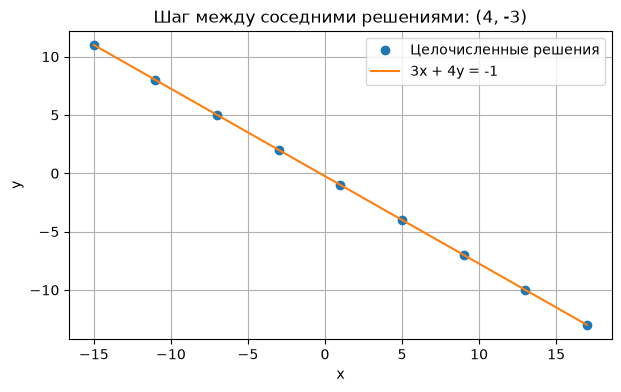

In [18]:
import matplotlib.pyplot as plt
x0,y0,dx,dy = solve_linear_diophantine(3,4,-1)
ts = list(range(-4,5))
xs,ys = [x0+dx*t for t in ts],[y0+dy*t for t in ts]
assert all(3*x+4*y == -1 for x,y in zip(xs,ys))
assert all((xs[i+1]-xs[i],ys[i+1]-ys[i]) == (4,-3) for i in range(len(ts)-1))
fig,ax = plt.subplots(figsize=(7,4))
ax.plot(xs,ys,'o',label='Целочисленные решения')
ax.plot([min(xs),max(xs)],[(-1-3*min(xs))/4,(-1-3*max(xs))/4],label='3x + 4y = -1')
ax.set(xlabel='x',ylabel='y',title='Шаг между соседними решениями: (4, -3)')
ax.grid(); ax.legend(); plt.show()

Все точки имеют вид $(1+4t,-1-3t)$. Подстановка даёт $3+12t-4-12t=-1$. Разность соседних точек равна $(4,-3)=(b/g,-a/g)$; график подтверждает уже доказанное алгебраическое свойство.

<img src="./figs/1.png" alt="Компьютер" width="500" height="400">

## 1.5. Обратный элемент по модулю: первое криптографически значимое следствие

Для $n\ge2$ обратный к $a$ элемент по модулю $n$ определяется сравнением

$$
ax\equiv1\pmod n.
\tag{1.22}
$$

Критерий существования:

$$
a^{-1}\pmod n\text{ существует}\iff\gcd(a,n)=1.
\tag{1.23}
$$

Действительно, при $\gcd(a,n)=1$ соотношение Безу даёт

$$
ax+ny=1.
\tag{1.24}
$$

Следовательно,

$$
ax\equiv1\pmod n.
$$

Обратное направление следует из представления $ax-1=kn$: тогда $ax-kn=1$, поэтому любой общий делитель $a$ и $n$ делит $1$.

### Контракт и корректность `mod_inverse`

Для `modulus >= 2` функция должна:

- вернуть наименьшего неотрицательного представителя $x$, если $\gcd(a,\texttt{modulus})=1$;
- отклонить вход, если обратного элемента не существует.

Ключевая строка

```python
g, x, _ = extended_gcd(a, modulus)
```

даёт

$$
ax+\texttt{modulus}\cdot y=g.
$$

Если $g=1$, то $x$ представляет обратный класс:

$$
ax\equiv1\pmod{\texttt{modulus}}.
$$

Возврат `x % modulus` не меняет класс вычетов, а только выбирает его канонического представителя

$$
0\le x<\texttt{modulus}.
$$

Таким образом, здесь особенно явно проявляется связь

$$
\boxed{\text{теорема о существовании}\longleftrightarrow\text{контракт функции}.}
$$

Расширенный алгоритм Евклида поэтому является не отдельной учебной техникой, а вычислительным механизмом деления в модульной арифметике.


In [19]:
def mod_inverse(a: int, modulus: int) -> int:
    if modulus < 2:
        raise ValueError("modulus must be >= 2")
    g, x, _ = extended_gcd(a, modulus)
    if g != 1:
        raise ValueError("inverse does not exist")
    return x % modulus

assert mod_inverse(7, 26) == 15
assert (7 * mod_inverse(7, 26)) % 26 == 1
assert mod_inverse(-3, 7) == 2

# Проверяем математический контракт на случайных допустимых входах.
for _ in range(100):
    modulus = secrets.randbelow(10_000 - 2) + 2
    a = secrets.randbelow(20_001) - 10_000
    if gcd(a, modulus) == 1:
        inv = mod_inverse(a, modulus)
        assert 0 <= inv < modulus
        assert (a * inv) % modulus == 1


<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Практика. Контракт, проверка и криптографический масштаб

1. Объясните, почему проверка `g != 1` выражает математическое условие существования обратного элемента, а `modulus < 2` задаёт программный контракт функции.
2. Проверьте 500 случайных пар $(a,n)$; когда `gcd(a, n) == 1`, сравните `mod_inverse(a, n)` с `pow(a, -1, n)`.
3. Для невзаимно простых пар убедитесь, что функция корректно отклоняет вход.
4. Объясните, почему отрицательный коэффициент Безу не является ошибкой и почему результат `x % modulus` является корректным представителем обратного класса.
5. Сгенерируйте модуль $n$ ровно из 2048 бит и случайное $1\le a<n$. Если $\gcd(a,n)\ne1$, выберите новое $a$. Затем измерьте время `mod_inverse(a, n)`, проверьте `(a * inv) % n == 1` и сравните результат с `pow(a, -1, n)`.
6. Объясните, почему расширенный алгоритм Евклида остаётся практически применимым при 2048-битных входах, тогда как перебор кандидатов на обратный элемент — нет.

</div>

In [20]:
from time import perf_counter
for _ in range(500):
    n = secrets.randbelow(10000)+2
    a = secrets.randbelow(20001)-10000
    if gcd(a,n) == 1:
        inv = mod_inverse(a,n)
        assert inv == pow(a,-1,n) and (a*inv)%n == 1
    else:
        try:
            mod_inverse(a,n)
        except ValueError:
            pass
        else:
            raise AssertionError('Обратный не существует')
n = random_exact_bits(2048)
while True:
    a = secrets.randbelow(n-1)+1
    if gcd(a,n) == 1:
        break
start = perf_counter(); inv = mod_inverse(a,n); elapsed = perf_counter()-start
assert (a*inv)%n == 1 and inv == pow(a,-1,n)
print('500 пар проверены; 2048-битный модуль: время, с =',elapsed)

500 пар проверены; 2048-битный модуль: время, с = 0.011414600070565939


**Ответы.** Из Безу $ax+ny=g$ следует существование обратного ровно при $g=1$; необходимость: общий делитель $a,n$ обязан делить 1. Условие $n\ge2$ задаёт выбранную область определения функции. Отрицательный $x$ допустим, а $x\bmod n$ принадлежит тому же классу и лежит в $[0,n)$. Расширенный Евклид требует $O(L)$ шагов и $O(L^2)$ битовых операций в классической модели; перебор до $n$ требует экспоненциального по $L$ числа кандидатов.

### 1.5.1. Линейные сравнения

Рассмотрим линейное сравнение

$$ax\equiv b\pmod n,\qquad n\ge 2. \tag{1.25}$$

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

**Теорема 1.4 (критерий разрешимости линейного сравнения).** Пусть

$$g=\gcd(a,n).$$

Тогда сравнение (1.25) имеет решение тогда и только тогда, когда

$$\boxed{g\mid b}. \tag{1.26}$$

Если условие (1.26) выполнено, то сравнение имеет ровно $g$ различных решений по модулю $n$.

</div>

Критерий существования уже можно предвидеть из теоремы 1.3: сравнение $ax\equiv b\pmod n$ эквивалентно существованию целого $y$, для которого $ax+ny=b$. Ниже мы ещё раз докажем критерий непосредственно в языке сравнений, одновременно закрепляя схему «необходимость + достаточность», а затем отдельно установим число решений.

**Доказательство.** Обозначим

$$P=\text{«сравнение }ax\equiv b\pmod n\text{ имеет решение»},$$

$$Q=\text{«}g\mid b\text{»},\qquad g=\gcd(a,n).$$

Теорема утверждает

$$P\leftrightarrow Q.$$

В формулировке теоремы $P$ — исследуемое свойство (разрешимость сравнения), а $Q$ — условие, являющееся критерием этого свойства. Поэтому необходимо доказать две импликации:

$$\underbrace{P\to Q}_{\text{необходимость условия }g\mid b}\qquad\text{и}\qquad\underbrace{Q\to P}_{\text{достаточность условия }g\mid b}.$$

Это ровно две части доказательства. Каждая доказанная импликация допускает два эквивалентных прочтения: например, $P\to Q$ одновременно означает, что $P$ достаточно для $Q$ и что $Q$ необходимо для $P$. В данной теореме нас интересует именно условие $Q$ как критерий свойства $P$, что уже задано формулировкой теоремы.

**1. Необходимость условия $g\mid b$.** Предположим, что сравнение (1.25) имеет решение. Тогда существует $x\in\mathbb Z$ такой, что

$$ax\equiv b\pmod n.$$

По определению сравнения по модулю это означает

$$n\mid(ax-b).$$

Следовательно, существует $k\in\mathbb Z$ такое, что

$$ax-b=nk.$$

Перенося $nk$ в левую часть, получаем $ax-nk=b$. Положив $y=-k$, записываем это равенство в форме целой линейной комбинации:

$$ax+ny=b. \tag{1.27}$$

Так как $g=\gcd(a,n)$, то $g\mid a$ и $g\mid n$. Поэтому $g$ делит любую целую линейную комбинацию чисел $a$ и $n$, в частности левую часть (1.27). Следовательно,

$$g\mid b.$$

Тем самым доказана импликация $P\to Q$, то есть **необходимость** условия $g\mid b$ для разрешимости сравнения.

**2. Достаточность условия $g\mid b$.** Теперь предположим, что

$$g\mid b.$$

Нужно показать, что сравнение (1.25) имеет решение. По соотношению Безу существуют $c,d\in\mathbb Z$ такие, что

$$ac+nd=g. \tag{1.28}$$

Так как $g\mid b$, число $b/g$ целое. Умножая (1.28) на $b/g$, получаем

$$a\left(c\frac bg\right)+n\left(d\frac bg\right)=b. \tag{1.29}$$

Следовательно,

$$a\left(c\frac bg\right)\equiv b\pmod n,$$

поэтому

$$x_0=c\frac bg \tag{1.30}$$

является одним из решений сравнения (1.25).

Тем самым доказана импликация $Q\to P$, то есть **достаточность** условия $g\mid b$ для разрешимости сравнения. Итак, критерий разрешимости доказан:

$$P\leftrightarrow Q.$$

Остаётся доказать вторую часть утверждения — определить число различных решений при выполнении $g\mid b$.

**3. Число решений.** Пусть условие $g\mid b$ выполнено. Мы уже знаем, что решение существует. Теперь требуется выяснить, сколько различных классов решений получается **по модулю $n$**.

Поскольку

$$g=\gcd(a,n),$$

можно записать

$$a=ga',\qquad n=gn'.$$

А из условия $g\mid b$ следует, что

$$b=gb'.$$

Иными словами, положим

$$a'=\frac ag,\qquad b'=\frac bg,\qquad n'=\frac ng.$$

При этом

$$\gcd(a',n')=1.$$

Действительно, если бы числа $a'$ и $n'$ имели общий делитель $d>1$, то число $gd$ было бы общим делителем $a$ и $n$, большим $g=\gcd(a,n)$, что невозможно.

Исходное сравнение эквивалентно условию

$$n\mid(ax-b).$$

Подставляя $a=ga'$, $b=gb'$ и $n=gn'$, получаем

$$gn'\mid g(a'x-b').$$

После сокращения общего множителя $g$ это равносильно

$$n'\mid(a'x-b'),$$

то есть приведённому сравнению

$$a'x\equiv b'\pmod{n'}. \tag{1.31}$$

Поскольку $\gcd(a',n')=1$, элемент $a'$ имеет обратный по модулю $n'$. Поэтому (1.31) имеет единственный класс решений по модулю $n'$:

$$x\equiv x_0\pmod{n'}.$$

Здесь важно различать **единственное решение по модулю $n'$** и единственное целое значение $x$. Запись $x\equiv x_0\pmod{n'}$ означает, что все целые решения имеют вид

$$x=x_0+tn',\qquad t\in\mathbb Z.$$

Так как $n'=n/g$, получаем

$$x=x_0+t\frac ng,\qquad t\in\mathbb Z.$$

Теперь эти целые решения нужно рассмотреть **по модулю $n$**. Поскольку

$$n=gn',$$

после $g$ шагов величины $n'$ получаем

$$x_0+gn'=x_0+n\equiv x_0\pmod n.$$

Следовательно, достаточно взять

$$t=0,1,\ldots,g-1.$$

Это даёт $g$ классов:

$$x_0,\quad x_0+n',\quad x_0+2n',\quad\ldots,\quad x_0+(g-1)n'.$$

Покажем, что они действительно попарно различны по модулю $n$. Пусть для некоторых $0\le i<j\le g-1$ выполняется

$$x_0+in'\equiv x_0+jn'\pmod n.$$

Тогда

$$n\mid(j-i)n'.$$

Так как $n=gn'$, это означает

$$g\mid(j-i).$$

Но

$$1\le j-i\le g-1,$$

поэтому $g$ не может делить $j-i$. Получили противоречие. Значит, указанные $g$ классов попарно различны по модулю $n$.

Следующий класс уже совпадает с первым:

$$x_0+gn'=x_0+n\equiv x_0\pmod n.$$

Таким образом, все различные решения исходного сравнения по модулю $n$ имеют вид

$$\boxed{x=x_0+k\frac ng,\qquad k=0,1,\ldots,g-1}. \tag{1.32}$$

Следовательно, при $g\mid b$ исходное сравнение имеет ровно $g$ различных решений по модулю $n$. $\square$

<div style="background-color: #243a30; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Пример 1.5. Случай нескольких решений

Решим

$$4x\equiv2\pmod{10}.$$

Имеем $g=\gcd(4,10)=2$ и $2\mid2$, поэтому решения существуют и их должно быть ровно два по модулю $10$. После деления на $g$:

$$2x\equiv1\pmod5.$$

Так как $2^{-1}\equiv3\pmod5$, получаем $x\equiv3\pmod5$. Следовательно, по модулю $10$:

$$\boxed{x\equiv3,\ 8\pmod{10}}.$$

Этот пример показывает, почему функция решения общего линейного сравнения должна уметь возвращать **все** решения, а не только один представитель.

</div>

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.8. Решение линейных сравнений

Реализуйте функцию

```python
def solve_linear(a: int, b: int, n: int) -> list[int]:
    ...
```

которая решает сравнение

$$ax\equiv b\pmod n,\qquad n\ge2,$$

и возвращает **все различные решения** в диапазоне $0\le x<n$, отсортированные по возрастанию. Если решений нет, функция должна вернуть пустой список `[]`.

Используйте `extended_gcd()` и доказанный выше критерий разрешимости; полный перебор $x=0,1,\ldots,n-1$ не допускается.

Проверьте, что

```python
solve_linear(4, 2, 10) == [3, 8]
solve_linear(2, 1, 4) == []
```

Затем с помощью функции решите

$$27x\equiv4\pmod{25}.$$

Для каждого возвращённого значения $x$ программно проверьте условие

```python
(a * x - b) % n == 0
```

Наконец, объясните:

1. почему условие `gcd(a, n) | b` определяет существование решения;
2. почему при $g=\gcd(a,n)>1$ и $g\mid b$ решений по модулю $n$ ровно $g$;
3. почему при $g=1$ решение единственно по модулю $n$ и задача сводится к умножению $b$ на обратный элемент к $a$.

</div>

In [21]:
def solve_linear(a, b, n):
    """n>=2; все решения ax=b (mod n) в [0,n), по возрастанию."""
    if n < 2:
        raise ValueError('n должно быть >= 2')
    g,u,_ = extended_gcd(a,n)
    if b % g:
        return []
    step = n//g
    x0 = (u*(b//g)) % step
    return [x0+k*step for k in range(g)]

assert solve_linear(4,2,10) == [3,8]
assert solve_linear(2,1,4) == []
assert solve_linear(27,4,25) == [2]
for a,b,n in [(4,2,10),(2,1,4),(27,4,25),(0,0,5),(0,1,5)]:
    xs = solve_linear(a,b,n)
    assert xs == sorted(set(xs))
    assert all(0 <= x < n and (a*x-b)%n == 0 for x in xs)
    print((a,b,n),xs)

(4, 2, 10) [3, 8]
(2, 1, 4) []
(27, 4, 25) [2]
(0, 0, 5) [0, 1, 2, 3, 4]
(0, 1, 5) []


**Ответ 1.8.** Сравнение эквивалентно диофантову уравнению $ax+ny=b$, разрешимому ровно при $g=\gcd(a,n)\mid b$. После деления на $g$ коэффициент $a/g$ обратим по модулю $n/g$, поэтому есть один класс $x_0\pmod{n/g}$. Его представители по модулю $n$ — $x_0+k(n/g)$, $0\le k<g$: их ровно $g$, все различны. При $g=1$ получаем единственное $x\equiv a^{-1}b\pmod n$. Для $27x\equiv4\pmod{25}$ имеем $2x\equiv4$, откуда $x\equiv2\pmod{25}$.

## 1.6. Быстрое модульное возведение в степень — центральная вычислительная операция

Наивный способ сначала вычислить $a^e$, а затем взять остаток по модулю $n$ непригоден для криптографических размеров. Даже повторное умножение с редукцией после каждого шага требует $O(e)$ модульных умножений.

Используем двоичное представление показателя:

$$
e=\sum_{i=0}^{k-1} e_i2^i,\qquad e_i\in\{0,1\}.
\tag{1.33}
$$

Тогда

$$
a^e=\prod_{i:e_i=1}a^{2^i}.
\tag{1.34}
$$

Последовательные квадраты позволяют вычислять

$$
a,a^2,a^4,a^8,\ldots \pmod n.
\tag{1.35}
$$

Число итераций имеет порядок $\log_2 e$, то есть порядок битовой длины показателя.

### От наивного метода к двоичному

Если $L=\ell(e)$ — битовая длина показателя, то $e$ имеет порядок $2^L$. Поэтому повторное умножение требует порядка

$$
O(e)=O(2^L)
$$

модульных умножений относительно размера представления показателя, тогда как двоичный метод использует

$$
O(\log e)=O(L)
$$

итераций.

Именно это различие делает модульное возведение в большую степень практически выполнимым в RSA, Диффи—Хеллмане и Эль-Гамале.

### Инвариант и доказательство корректности `mod_pow`

Пусть исходные значения основания и показателя равны $a$ и $E$. После приведения основания по модулю $n$ поддерживаем инвариант

$$
\boxed{
\texttt{result}\cdot \texttt{base}^{\,\texttt{e}}
\equiv
a^E
\pmod n.
}
$$

В начале

$$
\texttt{result}=1,\qquad
\texttt{base}\equiv a\pmod n,\qquad
\texttt{e}=E,
$$

поэтому инвариант выполнен.

Если текущий показатель нечётный, $\texttt{e}=2q+1$, алгоритм переносит один множитель `base` в `result`, затем заменяет `base` на `base**2` и `e` на $q$. Тогда

$$
(\texttt{result}\cdot\texttt{base})\,
(\texttt{base}^2)^q
= \texttt{result}\cdot\texttt{base}^{2q+1},
$$

поэтому значение левой части инварианта не меняется.

Если текущий показатель чётный, $\texttt{e}=2q$, то `result` не меняется, а

$$
\texttt{result}\,(\texttt{base}^2)^q
= \texttt{result}\cdot\texttt{base}^{2q}.
$$

Следовательно, инвариант сохраняется и в этом случае.

При завершении цикла $\texttt{e}=0$, поэтому из инварианта следует

$$
\texttt{result}\equiv a^E\pmod n.
$$

Возвращаемое значение является требуемым наименьшим неотрицательным представителем класса $a^E\bmod n$.

### Паспорт алгоритма `mod_pow`

**Контракт.** Вход: `modulus > 0`, `exponent >= 0`. Выход: целое число `r`, для которого

$$
0\le r<\texttt{modulus},
\qquad
r\equiv \texttt{base}^{\texttt{exponent}}\pmod{\texttt{modulus}}.
$$

**Арифметическая стоимость.** $O(\log e)$ модульных умножений для показателя $e$.

**Битовая стоимость.** Если $E=\ell(e)$, $L=\ell(n)$ и $M(L)$ — стоимость $L$-битного умножения (с редукцией того же асимптотического порядка), то полная стоимость равна $O(E\,M(L))$. При классическом умножении это $O(EL^2)$. Подробный вывод приведён ниже.

**Инженерное замечание.** Собственная реализация нужна для понимания алгоритма и доказательства корректности. В обычном Python для вычислений следует использовать `pow(base, exponent, modulus)`. Учебная реализация не является реализацией с постоянным временем выполнения и не должна использоваться как готовый промышленный криптографический примитив.


<div style="background-color: #243a30; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Пример 1.6. $7^{13}\bmod 23$

Так как $13=(1101)_2=8+4+1$,
$$7^{13}=7^8\cdot7^4\cdot7.$$
Все квадраты и произведения можно немедленно редуцировать по модулю 23. Именно эта схема масштабируется к криптографическим показателям.

</div>

In [22]:
def mod_pow(base: int, exponent: int, modulus: int) -> int:
    if modulus <= 0:
        raise ValueError("modulus must be positive")
    if exponent < 0:
        raise ValueError("this implementation expects exponent >= 0")

    result = 1 % modulus
    base %= modulus
    e = exponent

    while e:
        if e & 1:
            result = (result * base) % modulus
        base = (base * base) % modulus
        e >>= 1

    return result

assert mod_pow(7, 13, 23) == pow(7, 13, 23)
assert mod_pow(2, 0, 17) == 1

### Два направления двоичного алгоритма

Реализация `mod_pow` выше обрабатывает двоичную запись показателя **справа налево** (*right-to-left binary exponentiation*): на каждой итерации рассматривается младший бит текущего значения `e`, а `base` последовательно принимает значения

$$
a,a^2,a^4,a^8,\ldots \pmod n.
$$

Ту же двоичную структуру можно использовать в противоположном направлении. Пусть уже прочитанный слева префикс битов показателя задаёт число $p$, а текущий накопленный результат удовлетворяет

$$
r\equiv a^p\pmod n.
$$

Если следующий бит равен $b\in\{0,1\}$, новый префикс имеет значение

$$
p'=2p+b.
$$

Поэтому

$$
a^{p'}=a^{2p+b}=(a^p)^2a^b.
$$

Отсюда непосредственно получается шаг алгоритма:

$$
r\leftarrow r^2\pmod n,
$$

а при $b=1$ дополнительно

$$
r\leftarrow ra\pmod n.
$$

Так возникает **двоичное возведение в степень слева направо** (*left-to-right binary exponentiation*). В отличие от предыдущей реализации, здесь естественный инвариант формулируется через уже обработанный префикс показателя: после чтения префикса со значением $p$ выполняется $r\equiv a^p\pmod n$.

Оба направления используют $O(\log e)$ шагов и отражают одну математическую идею, но поддерживают разные состояния программы.

### Одинаковый результат — разная вычислительная стоимость

Для небольших входов математически эквивалентны все три записи:

```python
(base ** exponent) % modulus
mod_pow(base, exponent, modulus)
pow(base, exponent, modulus)
```

Однако вычислительно они принципиально различаются. Выражение `(base ** exponent) % modulus` сначала строит целое число $\texttt{base}^{\texttt{exponent}}$ и только затем выполняет редукцию. Учебные двоичные алгоритмы редуцируют промежуточные результаты по модулю на каждом шаге. Трёхаргументный `pow(base, exponent, modulus)` также выполняет модульное возведение в степень без явного построения гигантского значения $\texttt{base}^{\texttt{exponent}}$.

Поэтому при сравнении алгоритмов важно сначала анализировать **число и тип арифметических операций**, а измерение wall-clock time рассматривать как отдельный инженерный эксперимент: оно зависит не только от асимптотики, но и от реализации больших целых и встроенных операций Python.

In [23]:
def mod_pow_left_to_right(base: int, exponent: int, modulus: int) -> int:
    """Учебное left-to-right binary modular exponentiation."""
    if modulus <= 0:
        raise ValueError("modulus must be positive")
    if exponent < 0:
        raise ValueError("this implementation expects exponent >= 0")

    result = 1 % modulus
    base %= modulus

    for bit in bin(exponent)[2:]:
        result = (result * result) % modulus
        if bit == "1":
            result = (result * base) % modulus

    return result


def mod_pow_repeated(base: int, exponent: int, modulus: int) -> int:
    """Учебное повторное умножение с редукцией после каждого шага."""
    if modulus <= 0:
        raise ValueError("modulus must be positive")
    if exponent < 0:
        raise ValueError("this implementation expects exponent >= 0")

    result = 1 % modulus
    base %= modulus
    for _ in range(exponent):
        result = (result * base) % modulus
    return result


for base, exponent, modulus in [
    (7, 13, 23),
    (5, 90, 91),
    (-3, 17, 101),
    (2, 0, 17),
    (123, 456, 1),
]:
    expected = pow(base, exponent, modulus)
    assert mod_pow(base, exponent, modulus) == expected
    assert mod_pow_left_to_right(base, exponent, modulus) == expected
    assert mod_pow_repeated(base, exponent, modulus) == expected

### Битовая сложность `mod_pow`

Оценка $O(\log e)$ в паспорте `mod_pow` считает **модульные умножения**, а не битовые операции. Зафиксируем оба размера входа:

$$
E=\ell(e),\qquad L=\ell(n).
$$

В двоичном алгоритме выполняется $O(E)$ шагов. Все промежуточные основания и результаты после редукции лежат в диапазоне $0,\ldots,n-1$, поэтому их длина не превосходит $L$ бит.

Обозначим через $M(L)$ битовую стоимость умножения двух $L$-битных чисел. Если умножение вместе с последующей редукцией по $L$-битному модулю имеет тот же асимптотический порядок, одно модульное умножение стоит $O(M(L))$. Отсюда

$$
T_{\mathrm{mod\_pow}}(e,n)=O(E\,M(L))
=O(\log e\cdot M(\log n)).
$$

При классическом школьном умножении $M(L)=O(L^2)$, поэтому

$$
T_{\mathrm{mod\_pow}}=O(EL^2)
=O(\log e\cdot(\log n)^2).
$$

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Почему здесь два эксперимента?</strong> Время `mod_pow` зависит и от $E$, и от $L$. Если одновременно удваивать обе величины, невозможно по одному timing понять, какой фактор вызвал рост. Поэтому сначала фиксируем длину показателя и меняем длину модуля, затем фиксируем модуль и меняем длину показателя.

</div>

Эмпирический замер производительности (*benchmark*) ниже сравнивает учебную Python-реализацию `mod_pow` со встроенным `pow`. Он иллюстрирует тенденции, но не доказывает асимптотику: CPython использует собственные оптимизированные алгоритмы длинной арифметики, а постоянные расходы Python особенно заметны на малых размерах.

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

</div>

In [24]:
def _median_call_time(func, args_factory, repeats=5):
    samples = []
    for _ in range(repeats):
        args = args_factory()
        start = perf_counter()
        value = func(*args)
        samples.append(perf_counter() - start)
        # Возвращаем значение только для того, чтобы вычисление нельзя было считать "неиспользованным".
        assert isinstance(value, int)
    return median(samples)


bit_sizes = (256, 512, 1024, 2048, 4096)

# Эксперимент A: E фиксировано, меняется L = bit_length(modulus).
fixed_exponent_bits = 256
modulus_timings = []
for modulus_bits in bit_sizes:
    exponent = random_exact_bits(fixed_exponent_bits)

    def args_factory(mb=modulus_bits, e=exponent):
        modulus = random_exact_bits(mb) | 1
        base = secrets.randbelow(modulus)
        return base, e, modulus

    t_edu = _median_call_time(mod_pow, args_factory)
    t_builtin = _median_call_time(pow, args_factory)
    modulus_timings.append((modulus_bits, t_edu, t_builtin))

print("Эксперимент A: E = 256 бит, меняется L")
print(" L, bits | mod_pow, ms | pow, ms")
print("---------|-------------|--------")
for bits, t_edu, t_builtin in modulus_timings:
    print(f"{bits:8d} | {1000*t_edu:11.4f} | {1000*t_builtin:6.4f}")

# Эксперимент B: L фиксировано, меняется E = bit_length(exponent).
fixed_modulus_bits = 2048
modulus = random_exact_bits(fixed_modulus_bits) | 1
exponent_timings = []
for exponent_bits in bit_sizes:

    def args_factory(eb=exponent_bits, m=modulus):
        exponent = random_exact_bits(eb)
        base = secrets.randbelow(m)
        return base, exponent, m

    t_edu = _median_call_time(mod_pow, args_factory)
    t_builtin = _median_call_time(pow, args_factory)
    exponent_timings.append((exponent_bits, t_edu, t_builtin))

print("\nЭксперимент B: L = 2048 бит, меняется E")
print(" E, bits | mod_pow, ms | pow, ms")
print("---------|-------------|--------")
for bits, t_edu, t_builtin in exponent_timings:
    print(f"{bits:8d} | {1000*t_edu:11.4f} | {1000*t_builtin:6.4f}")

print("\nИнтерпретация: сравнивайте тенденции, а не пытайтесь по пяти точкам")
print("экспериментально 'доказать' конкретную степень асимптотики.")

Эксперимент A: E = 256 бит, меняется L
 L, bits | mod_pow, ms | pow, ms
---------|-------------|--------
     256 |      0.1472 | 0.0916
     512 |      0.3587 | 0.2368
    1024 |      0.9779 | 0.8197
    2048 |      3.1016 | 2.3779
    4096 |     11.5628 | 8.6962



Эксперимент B: L = 2048 бит, меняется E
 E, bits | mod_pow, ms | pow, ms
---------|-------------|--------
     256 |      3.4806 | 2.7285
     512 |      6.7369 | 4.9324
    1024 |     12.6554 | 10.3721
    2048 |     25.8106 | 19.0921
    4096 |     57.4701 | 39.4017

Интерпретация: сравнивайте тенденции, а не пытайтесь по пяти точкам
экспериментально 'доказать' конкретную степень асимптотики.


<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование 1.3. Наивное и быстрое модульное возведение в степень

1. До запуска выпишите биты показателя `13` и предскажите, на каких итерациях меняется `result` в `mod_pow`.
2. Для готовой right-to-left реализации явно проверьте инвариант
   $$
   \texttt{result}\cdot\texttt{base}^{\,\texttt{e}}
   \equiv a^E\pmod n
   $$
   на каждом шаге для нескольких небольших примеров.
3. Для `mod_pow_left_to_right` проследите обработанные префиксы двоичной записи показателя и на каждом шаге проверьте инвариант $r\equiv a^p\pmod n$, где $p$ — значение уже прочитанного префикса.
4. Сравните четыре способа вычисления:
   ```python
   (base ** exponent) % modulus
   mod_pow_repeated(base, exponent, modulus)
   mod_pow(base, exponent, modulus)
   pow(base, exponent, modulus)
   ```
   Сначала объясните различия **без измерения времени**: какие промежуточные числа строятся и сколько модульных умножений требуется.
5. Посчитайте число модульных умножений в `mod_pow_repeated`, `mod_pow` и `mod_pow_left_to_right`. Сравните результаты для показателей с битовой длиной $8,16,20,24$. Не запускайте повторное умножение там, где эксперимент становится бессмысленно дорогим.

**Challenge.** Возьмите два показателя одинаковой битовой длины $k$: $e_1=2^{k-1}$ (двоичная запись $10\ldots0$) и $e_2=2^k-1$ (двоичная запись $11\ldots1$). Для `mod_pow` и `mod_pow_left_to_right` посчитайте **отдельно** число возведений в квадрат и число умножений накопленного результата. Объясните различие через число единичных битов показателя — вес Хэмминга (*Hamming weight*, `int.bit_count()`).

Обратите внимание: в `mod_pow` на последней итерации `base` возводится в квадрат, хотя это значение уже не используется. Сколько таких лишних операций выполняется при каждом вызове? Исправьте реализацию и проверьте её на тех же тестах. Почему зависимость числа операций от битов **секретного** показателя опасна для криптографии и к каким алгоритмам (например, лестнице Монтгомери) это ведёт?

</div>

In [25]:
# Проверка обоих инвариантов на малых примерах.
for a,E,n in [(7,13,23),(-3,17,101),(2,0,17)]:
    r,b,e = 1%n,a%n,E
    while e:
        assert r*pow(b,e,n)%n == pow(a,E,n)
        if e&1:
            r = r*b%n
        b = b*b%n; e >>= 1
        assert r*pow(b,e,n)%n == pow(a,E,n)
    r,p = 1%n,0
    for bit in bin(E)[2:]:
        r = r*r%n
        if bit == '1': r = r*a%n
        p = 2*p+int(bit)
        assert r == pow(a,p,n)

print('Ebits | повторное умножение | квадраты RTL/LTR | умножения RTL/LTR')
for k in (8,16,20,24):
    e = (1<<k)-1
    print(k,e,k,e.bit_count())
    if k <= 16:
        assert mod_pow_repeated(7,e,101) == mod_pow(7,e,101) == pow(7,e,101)
for k in (8,16,20,24):
    for e in (1<<(k-1),(1<<k)-1):
        print('challenge:', k, e, 'квадратов',k,'умножений',e.bit_count())

def mod_pow_optimized(base, exponent, modulus):
    if modulus <= 0 or exponent < 0:
        raise ValueError('Нужны modulus>0 и exponent>=0')
    r,b,e = 1%modulus,base%modulus,exponent
    while e:
        if e&1: r = r*b%modulus
        e >>= 1
        if e: b = b*b%modulus
    return r

for _ in range(500):
    a,e,n = secrets.randbelow(2001)-1000,secrets.randbelow(10000),secrets.randbelow(1000)+1
    assert mod_pow_optimized(a,e,n) == mod_pow(a,e,n) == mod_pow_left_to_right(a,e,n) == pow(a,e,n)
for a,e,n in [(2,0,17),(0,0,1),(-3,17,101)]:
    assert mod_pow_optimized(a,e,n) == pow(a,e,n)

Ebits | повторное умножение | квадраты RTL/LTR | умножения RTL/LTR
8 255 8 8
16 65535 16 16
20 1048575 20 20
24 16777215 24 24
challenge: 8 128 квадратов 8 умножений 1
challenge: 8 255 квадратов 8 умножений 8
challenge: 16 32768 квадратов 16 умножений 1
challenge: 16 65535 квадратов 16 умножений 16
challenge: 20 524288 квадратов 20 умножений 1
challenge: 20 1048575 квадратов 20 умножений 20
challenge: 24 8388608 квадратов 24 умножений 1
challenge: 24 16777215 квадратов 24 умножений 24


**Ответы исследования 1.3.** $13=(1101)_2$: справа налево читаются 1,0,1,1, поэтому `result` обновляется на итерациях 1, 3, 4. Слева направо префиксы имеют значения 1,3,6,13. Инварианты проверены до и после шагов.

`a**e % n` строит целую степень длиной порядка $e\log_2|a|$ бит. Повторное умножение выполняет $e$ модульных умножений при ограниченных остатках. Обе двоичные версии выполняют при $e>0$ ровно $k$ квадратов и $w$ дополнительных умножений, где $k=e.bit_length()$, $w=e.bit_count()$: всего $k+w$. Встроенный `pow` также редуцирует промежуточные результаты и использует оптимизации реализации. Для показателей $2^k-1$ число операций: 255/16, 65535/32, 1048575/40, 16777215/48 (повторные/двоичные). Большие повторные циклы не запускались.

В challenge число квадратов одинаково ($k$), число дополнительных умножений равно 1 и $k$. В исходной RTL при каждом положительном показателе есть ровно один неиспользуемый последний квадрат; при нулевом — ни одного. Исправленная версия делает $k-1$ квадратов. Для LTR при нуле исходный цикл по строке '0' выполняет один квадрат. Зависимость ветвлений и числа операций от секретных битов может раскрывать их через время и другие побочные каналы. Лестница Монтгомери выравнивает схему операций, но Python и обычная длинная арифметика сами по себе не гарантируют постоянного времени.

## 1.7. Китайская теорема об остатках: от системы сравнений к представлению вычислений

Китайская теорема об остатках, КТО (*Chinese Remainder Theorem, CRT*) связывает несколько сравнений по взаимно простым модулям с одним классом вычетов по произведению этих модулей. Для криптографии важна не только возможность решить систему сравнений, но и более сильная вычислительная идея: арифметику по большому составному модулю можно представить через независимые вычисления по меньшим взаимно простым модулям.


<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Локальные координаты и глобальный класс.</strong>

При попарно взаимно простых $m_1,\ldots,m_k$ отображение

$$
x\longmapsto (x\bmod m_1,\ldots,x\bmod m_k)
$$

переводит один глобальный класс по модулю $N=m_1\cdots m_k$ в набор его локальных координат. КТО утверждает не только существование решения системы сравнений: она даёт обратный переход — по совместимым локальным координатам восстанавливает единственный глобальный класс по модулю $N$.

Поэтому далее полезно читать `crt_encode` как переход **global → local**, а `crt` и `garner_crt` — как конструктивное восстановление **local → global**. Именно этот взгляд позже появится снова в доказательстве корректности RSA по модулям $p$ и $q$ и в ускорении RSA-CRT.

</div>

### Сначала два модуля: КТО как уже знакомое линейное сравнение

Начнём с простейшего случая КТО. Пусть даны два взаимно простых модуля $m$ и $n$:

$$
\gcd(m,n)=1.
$$

Требуется найти все целые числа $x$, которые одновременно удовлетворяют системе сравнений

$$
\begin{cases}
x\equiv a\pmod m,\\
x\equiv b\pmod n.
\end{cases}
\tag{1.36}
$$

Иными словами, мы хотим решить систему (1.36) и понять, по какому модулю найденное решение определяется однозначно.

Из первого сравнения следует, что

$$
x=a+tm
\tag{1.37}
$$

для некоторого $t\in\mathbb Z$.

Теперь потребуем, чтобы такое число $x$ удовлетворяло и второму сравнению. Подставляя (1.37), получаем

$$
a+tm\equiv b\pmod n,
$$

или, что то же самое,

$$
mt\equiv b-a\pmod n.
$$

Мы получили линейное сравнение относительно неизвестного $t$.

Поскольку $\gcd(m,n)=1$, существует обратный элемент $m^{-1}\pmod n$. Поэтому

$$
t\equiv (b-a)m^{-1}\pmod n.
\tag{1.38}
$$

Следовательно, для некоторого $k\in\mathbb Z$

$$
t=(b-a)m^{-1}+kn,
$$

где $m^{-1}$ обозначает любой целый представитель обратного класса по модулю $n$.

Подставляя это выражение в (1.37), получаем все решения исходной системы:

$$
x=a+m(b-a)m^{-1}+kmn.
$$

Следовательно,

$$
\boxed{
x\equiv a+m(b-a)m^{-1}\pmod{mn}.
}
\tag{1.39}
$$

Таким образом, мы не только свели задачу к линейному сравнению, но и действительно нашли решение исходной системы: все её решения образуют один класс вычетов по модулю $mn$.

Остаётся проверить, что построенное число удовлетворяет обоим исходным сравнениям.

По модулю $m$:

$$
x\equiv a\pmod m,
$$

поскольку второе слагаемое в (1.39) содержит множитель $m$.

По модулю $n$, используя $mm^{-1}\equiv1\pmod n$, получаем

$$
x\equiv a+(b-a)mm^{-1}\equiv a+(b-a)\equiv b\pmod n.
$$

Итак, построенный класс действительно является решением системы (1.36).

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Что произошло?</strong>

Задача о двух условиях на $x$ свелась к уже знакомому линейному сравнению относительно вспомогательной переменной $t$:

$$
\boxed{
\begin{array}{c}
x\equiv a\pmod m\\
x\equiv b\pmod n
\end{array}}
\quad\Longrightarrow\quad
mt\equiv b-a\pmod n
\quad\Longrightarrow\quad
\boxed{x\pmod{mn}}.
$$

Именно эту конструкцию китайская теорема об остатках обобщает на произвольное число попарно взаимно простых модулей.

</div>

<div style="background-color: #243a30; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Пример 1.7. Классическая система

Рассмотрим систему сравнений

$$
\begin{cases}
x\equiv 2\pmod 3,\\
x\equiv 3\pmod 5,\\
x\equiv 2\pmod 7.
\end{cases}
$$

КТО утверждает, что эта система имеет единственный класс решений по модулю

$$
3\cdot5\cdot7=105.
$$

Наименьший неотрицательный представитель этого класса равен

$$
x=23.
$$

Проверим, что найденное число действительно удовлетворяет **каждому сравнению системы**:

$$
\begin{aligned}
23 &\equiv 2\pmod 3,\\
23 &\equiv 3\pmod 5,\\
23 &\equiv 2\pmod 7.
\end{aligned}
$$

Следовательно,

$$
\boxed{x\equiv23\pmod{105}}
$$

— решение исходной системы сравнений.

</div>

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

<strong>Лемма 1.2. Взаимная простота с произведением</strong>

Если $\gcd(r,s)=1$ и $\gcd(r,t)=1$, то $\gcd(r,st)=1$. Как следствие, если $n_1,\ldots,n_k$ попарно взаимно просты, то каждое $n_i$ взаимно просто с произведением всех остальных модулей, а также $\gcd(n_1\cdots n_{i-1},\,n_i)=1$.

</div>

**Доказательство.** По соотношению Безу существуют целые $u,v,u',v'$ такие, что

$$
ur+vs=1,\qquad u'r+v't=1.
$$

Перемножив эти равенства, получаем

$$
r\,(uu'r+uv't+u'vs)+(vv')\,st=1.
$$

Любой общий делитель $r$ и $st$ делит левую часть, то есть делит $1$. Следовательно, $\gcd(r,st)=1$. Следствие получается индукцией по числу сомножителей. $\square$

Лемма используется ниже дважды: для существования обратных элементов $N_i^{-1}\pmod{n_i}$ и для единственности решения по модулю $N$.

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

<strong>Теорема 1.5. Китайская теорема об остатках</strong>

Пусть $n_1,\ldots,n_k\ge2$ попарно взаимно просты. Тогда система

$$
x\equiv a_i\pmod{n_i},\qquad i=1,\ldots,k
\tag{1.40}
$$

имеет решение, причём это решение единственно по модулю

$$
N=\prod_{i=1}^{k}n_i.
\tag{1.41}
$$

</div>

**Доказательство существования.**

Для каждого $i$ положим

$$
N_i=\frac{N}{n_i},\qquad
M_i=N_i^{-1}\pmod{n_i}.
\tag{1.42}
$$

Число $N_i$ является произведением всех модулей, кроме $n_i$. Поскольку модули попарно взаимно просты, по лемме 1.2

$$
\gcd(N_i,n_i)=1,
$$

а значит, обратный элемент $M_i$ существует.

Определим **базисный элемент КТО**

$$
e_i=N_iM_i.
\tag{1.43}
$$

Посмотрим, какие остатки имеет $e_i$ по модулям $n_1,\ldots,n_k$.

По модулю $n_i$ из определения $M_i$ получаем

$$
e_i=N_iM_i\equiv1\pmod{n_i}.
$$

Если же $j\ne i$, то число $N_i$ содержит $n_j$ в качестве множителя, поэтому

$$
N_i\equiv0\pmod{n_j},
$$

и, следовательно,

$$
e_i=N_iM_i\equiv0\pmod{n_j}.
$$

Таким образом,

$$
e_i\equiv
\begin{cases}
1\pmod{n_i},\\
0\pmod{n_j},&j\ne i.
\end{cases}
\tag{1.44}
$$

Теперь используем это свойство для построения решения исходной системы.

Умножим $e_i$ на требуемый остаток $a_i$. Тогда

$$
a_i e_i\equiv
\begin{cases}
a_i\pmod{n_i},\\
0\pmod{n_j},&j\ne i.
\end{cases}
$$

Иными словами, слагаемое $a_i e_i$ обеспечивает требуемый остаток $a_i$ по модулю $n_i$ и одновременно даёт нулевой остаток по всем остальным модулям.

Поэтому, если сложить такие слагаемые для всех $i$,

$$
a_1e_1+a_2e_2+\cdots+a_ke_k,
$$

то по каждому модулю $n_i$ в этой сумме останется ровно тот остаток $a_i$, который требуется в $i$-м сравнении исходной системы.

Это подсказывает следующую конструкцию:

$$
\boxed{
x\equiv\sum_{i=1}^{k}a_i e_i
=\sum_{i=1}^{k}a_iN_iM_i
\pmod N.
}
\tag{1.45}
$$

Проверим непосредственно, что построенный класс действительно является решением.

Зафиксируем произвольный индекс $i$ и рассмотрим сумму из (1.45) по модулю $n_i$:

$$
x\equiv
a_1e_1+\cdots+a_ie_i+\cdots+a_ke_k
\pmod{n_i}.
$$

Согласно (1.44), для каждого $j\ne i$

$$
e_j\equiv0\pmod{n_i},
$$

поэтому все соответствующие слагаемые исчезают. Для оставшегося слагаемого имеем

$$
e_i\equiv1\pmod{n_i},
$$

откуда

$$
x\equiv a_i e_i\equiv a_i\pmod{n_i}.
$$

Индекс $i$ был выбран произвольно. Следовательно, построенное по формуле (1.45) число удовлетворяет каждому сравнению системы (1.40).

Таким образом, решение системы существует.

**Доказательство единственности.**

Пусть $x$ и $y$ — два решения системы (1.40). Тогда для каждого $i$

$$
n_i\mid(x-y).
$$

Покажем сначала вспомогательный факт: если

$$
\gcd(r,s)=1,\qquad r\mid d,\qquad s\mid d,
$$

то

$$
rs\mid d.
$$

Поскольку $r\mid d$, существует $q\in\mathbb Z$ такое, что

$$
d=rq.
$$

Кроме того, $\gcd(r,s)=1$, поэтому по соотношению Безу существуют $u,v\in\mathbb Z$ такие, что

$$
ur+vs=1.
$$

Умножим это равенство на $q$:

$$
urq+vsq=q.
$$

Первое слагаемое делится на $s$, поскольку

$$
rq=d
$$

и по условию $s\mid d$. Второе слагаемое $vsq$ также делится на $s$. Следовательно, вся левая часть делится на $s$, а значит,

$$
s\mid q.
$$

По определению делимости существует $q'\in\mathbb Z$ такое, что

$$
q=sq'.
$$

Подставляя это представление в $d=rq$, получаем

$$
d=rq=r(sq')=rsq'.
$$

Следовательно,

$$
rs\mid d.
$$

Применим этот факт индукцией по числу модулей. Если уже доказано $n_1\cdots n_{i-1}\mid(x-y)$ и при этом $n_i\mid(x-y)$, то, поскольку по лемме 1.2 $\gcd(n_1\cdots n_{i-1},\,n_i)=1$, получаем $n_1\cdots n_i\mid(x-y)$. В итоге

$$
N=n_1\cdots n_k\mid(x-y).
$$

Следовательно,

$$
x\equiv y\pmod N.
$$

Таким образом, решение единственно по модулю $N$. $\square$

### Представление числа системой остатков

КТО можно читать и в обратном направлении. Каждому классу $[x]_N$ сопоставим кортеж его остатков:

$$
\Phi([x]_N)
= ([x]_{n_1},\ldots,[x]_{n_k}).
\tag{1.46}
$$

Теорема утверждает, что это соответствие взаимно однозначно: кортеж остатков по попарно взаимно простым модулям однозначно определяет класс по модулю $N$.

Позднее, после введения конечных колец, мы сформулируем этот факт как изоморфизм

$$
\mathbb Z_N
\cong
\mathbb Z_{n_1}\times\cdots\times\mathbb Z_{n_k}.
$$

Сейчас нам достаточно конструктивного смысла: число можно **разложить** в систему остатков, выполнять вычисления покомпонентно, а затем **реконструировать** результат.

### Арифметика выполняется покомпонентно

Если

$$
\Phi(A)=(a_1,\ldots,a_k),\qquad
\Phi(B)=(b_1,\ldots,b_k),
$$

то совместимость сравнений со сложением и умножением даёт

$$
\Phi((A+B)\bmod N)
= ((a_1+b_1)\bmod n_1,\ldots,(a_k+b_k)\bmod n_k),
\tag{1.47}
$$

$$
\Phi((A-B)\bmod N)
= ((a_1-b_1)\bmod n_1,\ldots,(a_k-b_k)\bmod n_k),
\tag{1.48}
$$

$$
\Phi((AB)\bmod N)
= ((a_1b_1)\bmod n_1,\ldots,(a_kb_k)\bmod n_k).
\tag{1.49}
$$

Именно здесь появляется вычислительный смысл КТО:

$$
\boxed{
\text{арифметика по модулю }N
\longleftrightarrow
\text{независимая покомпонентная арифметика по модулям }n_i.
}
$$

<div style="background-color: #243a30; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #3a8f5c;">

### Пример 1.8. Вычисление через CRT-представление

Пусть

$$
N=8633=89\cdot97,\qquad
A=2345,\qquad B=6789.
$$

Разложим оба числа в систему остатков:

$$
\Phi(A)=(31,17),\qquad
\Phi(B)=(25,96).
$$

Сложение выполняется покомпонентно:

$$
\Phi(A+B)
= ((31+25)\bmod89,\,(17+96)\bmod97)
= (56,16).
$$

Для реконструкции используем

$$
N_1=97,\qquad N_2=89,
$$

$$
97^{-1}\equiv78\pmod{89},\qquad
89^{-1}\equiv12\pmod{97}.
$$

Тогда

$$
A+B
\equiv
56\cdot97\cdot78 + 16\cdot89\cdot12
\equiv501
\pmod{8633}.
$$

Прямая проверка даёт тот же результат:

$$
(2345+6789)\bmod8633=501.
$$

Таким образом, КТО не только восстанавливает число по остаткам, но и позволяет переносить вычисления в меньшие независимые модули.

</div>

### Паспорт алгоритмов `crt_encode` и `crt`

**`crt_encode(x, moduli)`**

- **Вход:** целое $x$ и список модулей.
- **Выход:** кортеж остатков $(x\bmod n_1,\ldots,x\bmod n_k)$.
- **Смысл:** переход от представителя класса по модулю $N$ к CRT-представлению.

**`crt(residues, moduli)`**

- **Вход:** непустые списки одинаковой длины `residues`, `moduli`, где каждый модуль не меньше $2$, а модули попарно взаимно просты.
- **Выход:** наименьший неотрицательный представитель единственного класса решений по модулю $N$.
- **Постусловие:** для каждого $i$ выполняется $x\bmod n_i=a_i\bmod n_i$.
- **Конструкция:** функция реализует формулы (1.41)–(1.45) и использует уже построенную `mod_inverse()`.
- **Стоимость:** выполняются $k$ вычислений обратного элемента и линейное число дополнительных операций с длинными целыми; полная битовая стоимость зависит от размеров модулей.
- **Дальнейшее применение:** позднее та же идея будет использована для ускорения приватной операции RSA.

Разложение и реконструкция удовлетворяют важному контракту

$$
\boxed{
\operatorname{crt}
(\operatorname{crt\_encode}(x))
= x\bmod N.
}
\tag{1.50}
$$

Это равенство является естественным свойством для автоматического тестирования реализации.


In [26]:
from math import prod

def crt_encode(x: int, moduli: list[int]) -> list[int]:
    if not moduli:
        raise ValueError("moduli must be non-empty")
    if any(n < 2 for n in moduli):
        raise ValueError("all moduli must be >= 2")
    return [x % n for n in moduli]


def crt(residues: list[int], moduli: list[int]) -> int:
    if len(residues) != len(moduli) or not residues:
        raise ValueError("residues and moduli must have equal non-zero length")
    if any(n < 2 for n in moduli):
        raise ValueError("all moduli must be >= 2")

    for i in range(len(moduli)):
        for j in range(i + 1, len(moduli)):
            if gcd(moduli[i], moduli[j]) != 1:
                raise ValueError("moduli must be pairwise coprime")

    N = prod(moduli)
    x = 0

    for a_i, n_i in zip(residues, moduli):
        N_i = N // n_i
        M_i = mod_inverse(N_i, n_i)
        e_i = N_i * M_i
        x += a_i * e_i

    return x % N


# Классическая система:
x = crt([2, 3, 2], [3, 5, 7])
assert x == 23
assert crt_encode(x, [3, 5, 7]) == [2, 3, 2]

# Пример с арифметикой по модулю 8633:
moduli = [89, 97]
A, B = 2345, 6789
A_crt = crt_encode(A, moduli)
B_crt = crt_encode(B, moduli)

sum_crt = [
    (a + b) % n
    for a, b, n in zip(A_crt, B_crt, moduli)
]
sum_reconstructed = crt(sum_crt, moduli)

assert A_crt == [31, 17]
assert B_crt == [25, 96]
assert sum_crt == [56, 16]
assert sum_reconstructed == 501
assert sum_reconstructed == (A + B) % prod(moduli)

# Property test для encode -> reconstruct:
for value in [0, 1, 23, 501, 2345, 6789, 100_000]:
    assert crt(crt_encode(value, moduli), moduli) == value % prod(moduli)


### Последовательная реконструкция: алгоритм Гарнера

Формула (1.45) строит решение КТО сразу через базисные элементы $N_iM_i$. Есть и другой конструктивный взгляд: можно восстанавливать решение **последовательно**, добавляя по одному новому модулю. Эта схема называется **алгоритмом Гарнера** (*Garner's algorithm*).

Пусть после обработки первых $i-1$ модулей уже построено число $x$, удовлетворяющее первым $i-1$ сравнениям, и пусть

$$
M=m_1m_2\cdots m_{i-1}.
$$

Все числа вида

$$
x'=x+tM
$$

сохраняют уже выполненные сравнения, потому что $M$ делится на каждый из модулей $m_1,\ldots,m_{i-1}$. Чтобы добавить условие

$$
x'\equiv a_i\pmod{m_i},
$$

надо решить линейное сравнение

$$
Mt\equiv a_i-x\pmod{m_i}.
$$

Поскольку модули попарно взаимно просты, по лемме 1.2 $\gcd(M,m_i)=1$, поэтому $M^{-1}\pmod{m_i}$ существует и

$$
t\equiv(a_i-x)M^{-1}\pmod{m_i}.
$$

После выбора наименьшего неотрицательного представителя $t$ выполняем обновление

$$
\boxed{
x\leftarrow x+M\bigl((a_i-x)M^{-1}\bmod m_i\bigr),
\qquad
M\leftarrow Mm_i.
}
\tag{1.51}
$$

**Инвариант.** После обработки первых $i$ модулей число $x$ удовлетворяет

$$
x\equiv a_j\pmod{m_j},
\qquad j=1,\ldots,i,
$$

и лежит в диапазоне $0\le x<m_1\cdots m_i$.

Почему инвариант сохраняется? Старые сравнения не меняются, потому что добавляется кратное $M$. Новое сравнение выполняется по выбору коэффициента $t$. Кроме того, $0\le t\le m_i-1$ и $0\le x<M$, поэтому

$$
0\le x+tM<M+(m_i-1)M=m_iM.
$$

Значит, после каждого шага $x$ уже является наименьшим неотрицательным представителем построенного класса по текущему произведению модулей.

Для двух модулей эта конструкция в точности возвращает уже выведенную формулу (1.39): при $M=m$ имеем

$$
x=a+m\bigl((b-a)m^{-1}\bmod n\bigr).
$$

То есть алгоритм Гарнера здесь не является новой теоремой: это **алгоритмическая организация конструктивной КТО**, последовательно использующая тот же переход «старое решение $+$ кратное произведению уже обработанных модулей».

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

</div>

In [27]:
def garner_crt(residues: list[int], moduli: list[int]) -> int:
    """Reconstruct the least non-negative CRT solution sequentially."""
    if len(residues) != len(moduli) or not residues:
        raise ValueError("residues and moduli must have equal non-zero length")
    if any(n < 2 for n in moduli):
        raise ValueError("all moduli must be >= 2")

    for i in range(len(moduli)):
        for j in range(i + 1, len(moduli)):
            if gcd(moduli[i], moduli[j]) != 1:
                raise ValueError("moduli must be pairwise coprime")

    x = residues[0] % moduli[0]
    M = moduli[0]

    for a_i, m_i in zip(residues[1:], moduli[1:]):
        t = ((a_i - x) * mod_inverse(M, m_i)) % m_i
        x += t * M
        M *= m_i

    return x


# Классическая система и перекрёстная проверка с crt().
assert garner_crt([2, 3, 2], [3, 5, 7]) == 23
assert garner_crt([2, 3, 2], [3, 5, 7]) == crt([2, 3, 2], [3, 5, 7])

# Проверяем encode -> reconstruct для нескольких наборов модулей.
for test_moduli in ([5, 7, 11], [7, 11, 13], [89, 97]):
    modulus_product = prod(test_moduli)
    for value in (0, 1, 23, 501, modulus_product - 1, modulus_product + 17):
        residues = crt_encode(value, list(test_moduli))
        x_garner = garner_crt(residues, list(test_moduli))
        x_classic = crt(residues, list(test_moduli))
        assert x_garner == x_classic == value % modulus_product
        assert all(
            x_garner % m == a % m
            for a, m in zip(residues, test_moduli)
        )

# Контракт на некорректных модулях совпадает с crt().
try:
    garner_crt([1, 2], [6, 9])
except ValueError:
    pass
else:
    raise AssertionError("garner_crt must reject non-coprime moduli")

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Куда это ведёт: RSA-CRT.</strong>

Полное построение RSA появится позже, после простых чисел, функций Эйлера/Кармайкла и доказательства корректности RSA. Здесь зафиксируем только вычислительную мотивацию КТО.

Пусть впоследствии RSA-модуль будет иметь вид $n=pq$, где $p$ и $q$ — простые примерно по $t$ бит, так что $n$ имеет примерно $2t$ бит. Прямая приватная операция требует одного большого модульного возведения в степень по модулю $n$. Если использовать секретные множители $p,q$, то после теоремы, разрешающей редукцию показателя, вычисление можно будет разложить на две операции по модулям $p$ и $q$, а затем восстановить результат по КТО. Для двух модулей рекомбинация имеет особенно простой вид алгоритма Гарнера.

Почему часто говорят об ускорении примерно в четыре раза? В классической модели из §1.6 стоимость двоичного модульного возведения имеет порядок

$$
O(E L^2),
$$

где $E$ — длина показателя, $L$ — длина модуля. Для прямой RSA-операции обе величины имеют порядок $2t$, поэтому модель даёт величину, пропорциональную

$$
(2t)(2t)^2=8t^3.
$$

В CRT-варианте выполняются две операции с модулем и показателем порядка $t$ бит:

$$
2\cdot t\cdot t^2=2t^3.
$$

При пренебрежимо малой по сравнению с двумя возведениями в степень стоимости рекомбинации отношение равно примерно

$$
\frac{8t^3}{2t^3}=4.
$$

Это **модельная оценка**, а не обещание точного коэффициента для любой реализации. Реальное ускорение зависит от арифметики больших целых, алгоритма возведения в степень, аппаратуры и защит от атак по побочным каналам и сбоям. В RSA-блоке мы вернёмся к этой конструкции как к полноценной цепочке «построение → ускорение → атака → защита».


</div>

<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование 1.4. КТО как представление вычислений

1. Для системы $(2\bmod3,\ 3\bmod5,\ 2\bmod7)$ вычислите $N_i$, $M_i$ и базисные элементы $e_i$ вручную. Проверьте селективное свойство (1.44).

2. Сгенерируйте случайное целое $x$ и несколько попарно взаимно простых модулей. Выполните `crt_encode(x, moduli)`, затем реконструкцию двумя способами — `crt(...)` и `garner_crt(...)`. Проверьте свойство (1.50), совпадение двух реконструкций и все исходные сравнения.

3. Сгенерируйте два целых $A$ и $B$. Сравните:
   - прямое вычисление $(A+B)\bmod N$;
   - покомпонентное сложение CRT-представлений с последующей реконструкцией.

4. Повторите пункт 3 для умножения и экспериментально проверьте формулу (1.49).


5. **Challenge. КТО для не взаимно простых модулей.** Докажите, что система $x\equiv a\pmod m$, $x\equiv b\pmod n$ разрешима тогда и только тогда, когда
   $$
   a\equiv b\pmod{\gcd(m,n)},
   $$
   и что решение единственно по модулю $\operatorname{lcm}(m,n)$. Реализуйте `crt_general(residues, moduli)`, которая возвращает пару `(x, L)` — наименьшего неотрицательного представителя и модуль $L$ — или `None`, если система несовместна. Проверьте на системах $x\equiv 1\pmod 6,\ x\equiv 4\pmod 9$ (разрешима) и $x\equiv 1\pmod 6,\ x\equiv 2\pmod 9$ (несовместна). *Подсказка:* сведите задачу к линейному сравнению $mt\equiv b-a\pmod n$ из §1.5.1.

</div>


In [28]:
ms = [3,5,7]; N = math.prod(ms)
for i,m in enumerate(ms):
    Ni = N//m; Mi = mod_inverse(Ni,m); ei = Ni*Mi
    assert [ei%n for n in ms] == [int(i==j) for j in range(len(ms))]
    print('Ni,Mi,ei:',Ni,Mi,ei)
for ms in ([3,5,7],[5,7,11],[89,97]):
    N = math.prod(ms)
    for _ in range(100):
        x = secrets.randbits(256)-secrets.randbits(256)
        rs = crt_encode(x,ms)
        assert crt(rs,ms) == garner_crt(rs,ms) == x%N
        assert all(crt(rs,ms)%m == r for r,m in zip(rs,ms))
        A,B = secrets.randbits(256),secrets.randbits(256)
        ar,br = crt_encode(A,ms),crt_encode(B,ms)
        for vals,expected in [([(u+v)%m for u,v,m in zip(ar,br,ms)],(A+B)%N), ([(u*v)%m for u,v,m in zip(ar,br,ms)],(A*B)%N)]:
            assert crt(vals,ms) == garner_crt(vals,ms) == expected

def crt_general(residues, moduli):
    if not residues or len(residues) != len(moduli) or any(m<2 for m in moduli):
        raise ValueError('Нужны равные непустые списки и модули >=2')
    x,L = 0,1
    for a,m in zip(residues,moduli):
        g,u,_ = extended_gcd(L,m)
        if (a-x)%g: return None
        t = ((a-x)//g*u)%(m//g)
        x += L*t; L *= m//g; x %= L
    return x,L

assert crt_general([1,4],[6,9]) == (13,18)
assert crt_general([1,2],[6,9]) is None
print('Обобщённая КТО:',crt_general([1,4],[6,9]))

Ni,Mi,ei: 35 2 70
Ni,Mi,ei: 21 1 21
Ni,Mi,ei: 15 1 15
Обобщённая КТО: (13, 18)


**Ответы исследования 1.4.** $N=105$, $N_i=(35,21,15)$, $M_i=(2,1,1)$, $e_i=(70,21,15)$. Остатки базисных элементов — $(1,0,0)$, $(0,1,0)$, $(0,0,1)$. $2\cdot70+3\cdot21+2\cdot15=233\equiv23\pmod{105}$. Сложение и умножение покомпонентны благодаря совместимости сравнений; единственность КТО даёт совпадение реконструкций.

**Обобщение.** Пусть $g=\gcd(m,n)$. Если решение существует, $g\mid(x-a)$ и $g\mid(x-b)$, значит $g\mid(b-a)$. Обратно, положим $x=a+mt$; требуется $mt\equiv b-a\pmod n$, разрешимое ровно при $g\mid(b-a)$. После деления на $g$ значение $t$ единственно по модулю $n/g$, поэтому $x$ единственно по модулю $mn/g=\operatorname{lcm}(m,n)$. Последовательное объединение сохраняет все предыдущие сравнения. Для первой системы получаем $x\equiv13\pmod{18}$; вторая несовместна, поскольку $1\not\equiv2\pmod3$.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.9. Подсчёт по остаткам

Известно, что в школе учится **меньше 1000 учеников**. Считать всех учеников по одному неудобно, поэтому их несколько раз строят в ряды.

- При построении по $5$ человек в ряд остаётся $1$ ученик.
- При построении по $8$ человек в ряд остаются $2$ ученика.
- При построении по $19$ человек в ряд остаются $3$ ученика.

1. Запишите соответствующую систему сравнений.
2. Проверьте, применима ли китайская теорема об остатках в форме теоремы 1.5.
3. Найдите класс решений по модулю $5\cdot8\cdot19$.
4. Используя условие $0<x<1000$, определите точное количество учеников.
5. Проверьте ответ прямой подстановкой во все три сравнения.

**Контекст.** Такие задачи часто формулируются как задачи о подсчёте людей или предметов по остаткам. Например, если около тысячи солдат последовательно строятся в ряды по $7$, $8$ и $9$ человек, три остатка определяют численность **по модулю**

$$
7\cdot8\cdot9=504.
$$

КТО сама по себе восстанавливает класс вычетов по модулю $504$; дополнительная информация о диапазоне возможной численности нужна, чтобы выбрать конкретного представителя этого класса.

</div>


In [29]:
ms,rs = [5,8,19],[1,2,3]
assert all(gcd(ms[i],ms[j]) == 1 for i in range(3) for j in range(i))
x = crt(rs,ms); N = math.prod(ms)
candidates = [x+k*N for k in range(-2,3) if 0 < x+k*N < 1000]
assert all(all(v%m == r for r,m in zip(rs,ms)) for v in candidates)
print('Класс:',x,'по модулю',N,'; кандидаты:',candidates)

Класс: 706 по модулю 760 ; кандидаты: [706]


**Ответ 1.9.** Система: $x\equiv1\pmod5$, $x\equiv2\pmod8$, $x\equiv3\pmod{19}$. Модули попарно взаимно просты, поэтому КТО применима. Получается $x\equiv706\pmod{760}$. В диапазоне $0<x<1000$ только 706: предыдущий представитель −54, следующий 1466. Проверка: $706=5\cdot141+1=8\cdot88+2=19\cdot37+3$. В школе **706 учеников**.

### Взгляд вперёд: теорема Вильсона — критерий простоты и вычислительная ловушка

Перед итоговой лабораторной полезно увидеть ещё один пример того, как уже построенный инструментарий приводит к следующей теме курса — **простым числам**. Здесь важен не новый эффективный алгоритм, а различие между математически точным критерием и вычислительно пригодным тестом.

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

<strong>Теорема 1.6. Теорема Вильсона</strong>

Для целого $n>1$ следующие утверждения эквивалентны:

1. $n$ — простое число;
2. выполняется сравнение

$$
\boxed{(n-1)!\equiv -1\pmod n.}
\tag{1.52}
$$

</div>

**Доказательство.** Покажем обе импликации.

**Шаг 1. Простота $\Rightarrow$ сравнение (1.52).** Пусть $p$ — простое число. При $p=2$ утверждение непосредственно проверяется:

$$
1!\equiv1\equiv-1\pmod2.
$$

Пусть теперь $p>2$. Для каждого $a\in\{1,2,\ldots,p-1\}$ имеем $\gcd(a,p)=1$, поэтому существует единственный обратный класс $a^{-1}\pmod p$. Если $a$ не совпадает со своим обратным, множители $a$ и $a^{-1}$ можно объединить в пару с произведением $1$ по модулю $p$.

Остаётся выяснить, какие элементы совпадают со своими обратными. Условие

$$
a\equiv a^{-1}\pmod p
$$

эквивалентно

$$
a^2\equiv1\pmod p,
$$

то есть

$$
p\mid(a-1)(a+1).
$$

Поскольку $p$ простое, из делимости произведения следует

$$
a\equiv1\pmod p
\qquad\text{или}\qquad
 a\equiv-1\pmod p.
$$

Значит, все ненулевые классы, кроме $1$ и $-1$, разбиваются на пары $a,a^{-1}$, произведение каждой из которых равно $1$ по модулю $p$. Поэтому

$$
(p-1)!\equiv 1\cdot(-1)\equiv-1\pmod p.
$$

**Шаг 2. Сравнение (1.52) $\Rightarrow$ простота.** Предположим, что $n>1$ и

$$
(n-1)!\equiv-1\pmod n.
$$

Допустим противное: $n$ составно. Тогда существует собственный делитель $d$ такой, что

$$
1<d<n.
$$

Поскольку $d$ входит среди множителей $1,2,\ldots,n-1$, имеем

$$
d\mid(n-1)!.
$$

Но из (1.52) следует $n\mid((n-1)!+1)$, а значит, поскольку $d\mid n$,

$$
d\mid((n-1)!+1).
$$

Следовательно, $d$ делит разность $((n-1)!+1)-(n-1)!=1$, что невозможно при $d>1$. Получили противоречие. Значит, $n$ простое. $\square$

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Почему это важно вычислительно?</strong> Теорема Вильсона даёт точный критерий простоты, но непосредственная проверка требует порядка $n$ модульных умножений. Если $L=\ell(n)$ — битовая длина входа, то $n$ имеет порядок $2^L$. Даже при классической стоимости одного модульного умножения порядка $O(L^2)$ прямое вычисление факториала по модулю $n$ имеет грубую оценку

$$
O(nL^2)=O(2^L L^2).
$$

Таким образом, точный математический критерий сам по себе ещё не даёт эффективного алгоритма. В блоке о простых числах мы вернёмся к вопросу: как проверять простоту за время, полиномиальное по битовой длине или практически близкое к этому?

</div>

Связь с уже построенными функциями тоже содержательна. В доказательстве мы используем условие $a^2\equiv1\pmod p$, поэтому `mod_pow(a, 2, p)` можно использовать для контрольной проверки ключевого шага доказательства. А модульное произведение можно вычислить независимо по нескольким попарно взаимно простым модулям и восстановить по `crt()` или `garner_crt()`: это проверяет согласованность локальных вычислений с глобальной реконструкцией КТО.

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

</div>

In [30]:
def wilson_product(n: int) -> int:
    """Return (n - 1)! modulo n for n > 1."""
    if n <= 1:
        raise ValueError("n must be > 1")

    result = 1
    for a in range(1, n):
        result = (result * a) % n
    return result


# 1. Теорема Вильсона на известных малых простых и составных числах.
known_primes = {2, 3, 5, 7, 11, 13, 17, 19, 23, 29}
for n in range(2, 31):
    satisfies_wilson = wilson_product(n) == (n - 1) % n
    assert satisfies_wilson == (n in known_primes)

# 2. Контрольная проверка ключевого шага доказательства через mod_pow.
for p in sorted(known_primes):
    self_inverse = [a for a in range(1, p) if mod_pow(a, 2, p) == 1]
    expected = [1] if p == 2 else [1, p - 1]
    assert self_inverse == expected

# 3. Одно и то же модульное произведение: прямое вычисление и CRT-реконструкция.
def modular_product_upto(k: int, modulus: int) -> int:
    if k < 0:
        raise ValueError("k must be non-negative")
    if modulus < 2:
        raise ValueError("modulus must be >= 2")

    result = 1
    for a in range(1, k + 1):
        result = (result * a) % modulus
    return result


moduli = [11, 13, 17]
M = prod(moduli)
k = 20
residues = [modular_product_upto(k, m) for m in moduli]
direct = modular_product_upto(k, M)

assert crt(residues, moduli) == direct
assert garner_crt(residues, moduli) == direct

print(" n | (n-1)! mod n | Wilson")
print("---|--------------|-------")
for n in range(2, 21):
    value = wilson_product(n)
    print(f"{n:2d} | {value:12d} | {value == (n - 1) % n}")

 n | (n-1)! mod n | Wilson
---|--------------|-------
 2 |            1 | True
 3 |            2 | True
 4 |            2 | False
 5 |            4 | True
 6 |            0 | False
 7 |            6 | True
 8 |            0 | False
 9 |            0 | False
10 |            0 | False
11 |           10 | True
12 |            0 | False
13 |           12 | True
14 |            0 | False
15 |            0 | False
16 |            0 | False
17 |           16 | True
18 |            0 | False
19 |           18 | True
20 |            0 | False


<div style="background-color: #403823; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование 1.5. Теорема Вильсона: критерий и алгоритм

1. До запуска кода предскажите значения $(n-1)!\bmod n$ для нескольких простых и составных $n$. Затем сравните прогноз с таблицей.
2. Для нескольких нечётных простых $p$ найдите все $a\in\{1,\ldots,p-1\}$, для которых `mod_pow(a, 2, p) == 1`. Объясните результат через доказательство теоремы 1.6.
3. Измените диапазон эксперимента и проверьте критерий (1.52) на всех $2\le n\le100$. Отделите экспериментальную проверку конечного диапазона от доказательства для всех $n$.
4. Для нескольких наборов попарно взаимно простых модулей вычислите $k!$ по модулю произведения модулей двумя путями: напрямую и через локальные остатки с последующей реконструкцией `crt()` и `garner_crt()`. Объясните, почему совпадение следует из единственности в КТО, а не из теоремы Вильсона.

</div>

In [31]:
# Прогноз: для 5,7,11 -> 4,6,10; для 4,6,8,9 -> 2,0,0,0.
predictions = {5:4,7:6,11:10,4:2,6:0,8:0,9:0}
for n,v in predictions.items():
    assert wilson_product(n) == v
    print(n,v)
def is_prime_small(n):
    return n >= 2 and all(n%d for d in range(2,math.isqrt(n)+1))
for n in range(2,101):
    assert (wilson_product(n) == n-1) == is_prime_small(n)
for p in (3,5,7,11,17,29):
    roots = [a for a in range(1,p) if mod_pow(a,2,p)==1]
    assert roots == [1,p-1]
    print('p =',p,'корни:',roots)
for ms in ([5,7,11],[11,13,17],[8,9,5]):
    N = math.prod(ms)
    for k in (0,3,6,20):
        rs = [modular_product_upto(k,m) for m in ms]
        assert crt(rs,ms) == garner_crt(rs,ms) == modular_product_upto(k,N)
print('Критерий проверен для 2..100; факториалы сверены через КТО.')

5 4
7 6
11 10
4 2
6 0
8 0
9 0
p = 3 корни: [1, 2]
p = 5 корни: [1, 4]
p = 7 корни: [1, 6]
p = 11 корни: [1, 10]
p = 17 корни: [1, 16]
p = 29 корни: [1, 28]
Критерий проверен для 2..100; факториалы сверены через КТО.


**Ответы исследования 1.5.** Прогнозы указаны перед вычислением. Для простого $p$ ненулевые элементы попарно объединяются с обратными; остаются 1 и −1, так что произведение равно −1. Из $(a-1)(a+1)\equiv0\pmod p$ при простом $p$ следует $a=1$ или $a=p-1$ среди выбранных представителей. Проверка до 100 — конечный эксперимент; общий критерий доказан в теореме 1.6, включая обратную импликацию через собственный делитель составного числа. Реконструкция факториала совпадает с прямым вычислением по единственности КТО: обе величины имеют одинаковые локальные остатки. Простота модулей для этой реконструкции не нужна — достаточно попарной взаимной простоты, что показывает набор (8,9,5).

## 1.8. Интегрированная вычислительная лабораторная работа: от формул к инструментарию

Теперь материал предварительной подготовки считается актуализированным. Цель лабораторной — проверить не запоминание определений, а способность связать математический контракт, корректность реализации, проверку свойств и вычислительный масштаб.


<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.10 — Комплексная задача. 2048-битный вычислительный инструментарий

Выполните единый эксперимент.

1. Сгенерируйте два случайных положительных числа примерно по 2048 бит.
2. Вычислите `gcd` и выполните перекрёстную проверку через `math.gcd`.
3. Для взаимно простой пары получите `(g, x, y)` и проверьте равенство Безу.
4. Выберите модуль `n` и обратимый элемент `a`; вычислите обратный элемент и выполните перекрёстную проверку через `pow(a, -1, n)`.
5. Вычислите $a^e\bmod n$ для большого $e$ собственной `mod_pow()` и через встроенную `pow`.
6. Постройте КТО-систему из нескольких попарно взаимно простых модулей, реконструируйте число через `crt()` и `garner_crt()`, проверьте совпадение результатов и все сравнения.
7. Для каждого алгоритма явно запишите **контракт** и математическое постусловие, которое проверяет ваш `assert`.
8. Для `gcd` и `mod_pow` укажите размер входа в битах и объясните, что именно означает приведённая в ноутбуке оценка арифметической сложности.
9. Для одного из алгоритмов отдельно напишите: что установлено математическим доказательством, что проверяется тестом и что исследуется экспериментом.
10. Кратко объясните, какие из этих операций будут непосредственно использованы в Диффи—Хеллмане и Эль-Гамале, а какие — в RSA.

</div>


In [32]:
a,b = random_exact_bits(2048),random_exact_bits(2048)
assert gcd(a,b) == math.gcd(a,b)
while gcd(a,b) != 1:
    b = random_exact_bits(2048)
g,x,y = extended_gcd(a,b)
assert g == 1 and a*x+b*y == g
n = b
inv = mod_inverse(a,n)
assert 0 <= inv < n and (a*inv)%n == 1 and inv == pow(a,-1,n)
e = random_exact_bits(2048)
assert mod_pow(a,e,n) == pow(a,e,n)
ms = []
while len(ms)<4:
    m = random_exact_bits(512)|1
    if all(gcd(m,q)==1 for q in ms): ms.append(m)
N = math.prod(ms); value = secrets.randbelow(N)
rs = crt_encode(value,ms)
xc,xg = crt(rs,ms),garner_crt(rs,ms)
assert 0 <= xc < N and xc == xg == value
assert all(xc%m == r for r,m in zip(rs,ms))
print('Размеры a,b,n,e:',a.bit_length(),b.bit_length(),n.bit_length(),e.bit_length())
print('Модули КТО:',[m.bit_length() for m in ms],'бит; произведение:',N.bit_length(),'бит')
print('Все проверки 2048-битного эксперимента пройдены.')

Размеры a,b,n,e: 2048 2048 2048 2048
Модули КТО: [512, 512, 512, 512] бит; произведение: 2047 бит
Все проверки 2048-битного эксперимента пройдены.


**Контракты и постусловия 1.10.** `gcd`: целые, не оба нулевые; результат — положительный НОД, проверяемый через `math.gcd`. `extended_gcd`: та же область; $g=\gcd(a,b)$ и $ax+by=g$. `mod_inverse`: $n\ge2$, $\gcd(a,n)=1$; $0\le u<n$, $au\equiv1\pmod n$. `mod_pow`: $n>0$, $e\ge0$; канонический остаток $a^e\bmod n$. `crt` и `garner_crt`: равные непустые списки остатков и попарно взаимно простых модулей $\ge2$; единственный $x\in[0,N)$, удовлетворяющий каждому сравнению. `assert` выше проверяют соответствующие равенства, диапазоны и совпадение независимых способов.

Здесь $a,b,n,e$ имеют ровно 2048 бит. Для Евклида $L=\max(\ell(a),\ell(b))$, число делений $O(L)$; это не число битовых операций. Для степени при $E=\ell(e)$ выполняется $O(E)$ модульных умножений; их стоимость зависит от $L=\ell(n)$, при школьной арифметике грубо $O(EL^2)$. Само значение показателя порядка $2^E$, но двоичный алгоритм не делает столько шагов.

Для `mod_pow` доказательство инварианта устанавливает правильность на всех допустимых входах и завершение при сдвигах показателя; тест сравнивает реализации на конкретных данных; замеры исследуют зависимость времени от длин модуля и показателя. Тесты и замеры не заменяют доказательства.

Диффи—Хеллман непосредственно использует модульные степени; Эль-Гамаль — также обратный к общему секрету при расшифровании. RSA использует НОД для проверки показателя, обратный при вычислении закрытой экспоненты, степени при шифровании и подписи, КТО для ускорения закрытых операций по простым множителям модуля.

### 1.8.1. Перенос в библиотеку `crypto_math` и автотесты

Функции этого ноутбука переносятся в пакет, который будет пополняться в следующих ноутбуках курса:

```text
crypto_math/
├── __init__.py
└── number_theory.py      # divides, gcd, extended_gcd, ..., crt, garner_crt
tests/
└── test_number_theory.py
```

Правила переноса:

- в `number_theory.py` попадают только функции с контрактами и докстрингами; эксперименты, таблицы и графики остаются в ноутбуке;
- внутри библиотеки запрещены готовые реализации изучаемых алгоритмов (`math.gcd`, `pow(a, -1, n)`, `sympy`, Sage) — они допустимы **только в тестах** как эталон;
- учебные `assert` проверки инварианта в `extended_gcd` можно оставить: они документируют доказательство; в функциях для замеров времени их нет.

Тесты формулируются как **свойства** (*property-based testing*), а не как сравнение с заранее выбранным ответом: коэффициенты Безу и частные решения не единственны. Библиотека `hypothesis` сама генерирует входы, включая крайние случаи (нули, отрицательные числа, большие значения), и при ошибке находит минимальный контрпример.

```python
# tests/test_number_theory.py
import math
import pytest
from hypothesis import given, strategies as st

from crypto_math.number_theory import (
    divides, gcd, extended_gcd, mod_inverse, mod_pow, crt, garner_crt,
)

nonzero_pairs = st.tuples(st.integers(), st.integers()).filter(lambda p: p != (0, 0))


@given(st.integers(), st.integers())
def test_divides_matches_definition(a, b):
    assert divides(a, b) == (b == 0 if a == 0 else b % a == 0)


@given(nonzero_pairs)
def test_gcd_matches_reference(pair):
    a, b = pair
    assert gcd(a, b) == math.gcd(a, b)


@given(nonzero_pairs)
def test_extended_gcd_bezout(pair):
    a, b = pair
    g, x, y = extended_gcd(a, b)
    assert g == math.gcd(a, b)
    assert a * x + b * y == g


def test_gcd_rejects_zero_zero():
    with pytest.raises(ValueError):
        gcd(0, 0)


@given(st.integers(), st.integers(min_value=2))
def test_mod_inverse_contract(a, n):
    if math.gcd(a, n) == 1:
        inv = mod_inverse(a, n)
        assert 0 <= inv < n and (a * inv) % n == 1
    else:
        with pytest.raises(ValueError):
            mod_inverse(a, n)


@given(st.integers(), st.integers(min_value=0, max_value=2**64), st.integers(min_value=1))
def test_mod_pow_matches_builtin(a, e, n):
    assert mod_pow(a, e, n) == pow(a, e, n)


MODULI = [3, 5, 7, 11, 13, 17]


@given(st.integers())
def test_crt_roundtrip(x):
    N = math.prod(MODULI)
    residues = [x % m for m in MODULI]
    assert crt(residues, MODULI) == garner_crt(residues, MODULI) == x % N
```

Запуск из корня проекта: `python -m pytest -q`. Необходимые пакеты: `pip install pytest hypothesis`.

<div style="background-color: #233447; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1.11. Библиотека и тесты

1. Перенесите функции ноутбука в `crypto_math/number_theory.py` и добавьте тесты для `solve_linear_diophantine` и `solve_linear`, сформулированные как свойства.
2. Добейтесь, чтобы `python -m pytest -q` проходил без ошибок.
3. Намеренно внесите ошибку (например, замените `-` на `+` в обновлении коэффициентов `extended_gcd`) и посмотрите, какой минимальный контрпример найдёт `hypothesis`. Верните исправление.

</div>


In [33]:
from pathlib import Path
import subprocess,sys,os
from hypothesis import find, strategies as st, settings
from crypto_math import number_theory

# Испорченная копия создаётся только в памяти; библиотека остаётся исправной.
import inspect
src = inspect.getsource(number_theory.extended_gcd)
bad_src = src.replace('old_s - q * s','old_s + q * s')
assert bad_src != src
scope = {}; exec(bad_src,scope)
def detects_bug(pair):
    a,b = pair
    try:
        g,x,y = scope['extended_gcd'](a,b)
    except AssertionError:
        return True
    return g != math.gcd(a,b) or a*x+b*y != g
counterexample = find(st.tuples(st.integers(min_value=1,max_value=100),st.integers(min_value=1,max_value=100)), detects_bug, settings=settings(max_examples=1000,derandomize=True,database=None))
print('Минимизированный Hypothesis контрпример в положительных парах:',counterexample)
assert detects_bug(counterexample)
a,b = counterexample
g,x,y = number_theory.extended_gcd(a,b)
assert g == math.gcd(a,b) and a*x+b*y == g
result = subprocess.run([sys.executable,'-m','pytest','-q','tests'],capture_output=True,text=True)
print(result.stdout)
if result.returncode: print(result.stderr)
assert result.returncode == 0

Минимизированный Hypothesis контрпример в положительных парах: (2, 3)


..........                                                               [100%]
10 passed in 2.23s



**Ответ 1.11.** Функции вынесены в `crypto_math/number_theory.py`, свойства — в `tests/test_number_theory.py`. В библиотеке нет готовых реализаций изучаемых алгоритмов; `math.prod` только перемножает модули. Тест диофантова уравнения проверяет критерий существования, частную точку и шаг семейства; тест линейного сравнения проверяет число, диапазон, уникальность и полноту решений на малых модулях. Намеренная ошибка внесена в изолированную копию функции, Hypothesis минимизирует контрпример в явно указанной стратегии положительных пар. Исходная функция после опыта проверена снова; точный контрпример и результат pytest сохранены в выводе ячейки.

### 1.8.2. Сверка с эталоном SageMath

По модели курса независимым эталоном служит SageMath. Ячейку ниже выполните в ноутбуке с ядром **SageMath 10.x** после переноса функций в `crypto_math` (см. §1.8.1). Если пакет ещё не создан, будут использованы функции, определённые выше в этом ноутбуке. В обычном ядре Python ячейка лишь сообщит, что Sage недоступен.

Код ячейки намеренно не использует `^` и переводит значения Sage в `int`: в ядре SageMath целочисленные литералы имеют тип `Integer`, а `^` означает возведение в степень, тогда как импортированный модуль `crypto_math` работает с обычными `int` Python.


In [34]:
import random

try:
    from sage.all import (
        xgcd as sage_xgcd,
        inverse_mod as sage_inverse_mod,
        power_mod as sage_power_mod,
        CRT_list as sage_crt,
    )
except ImportError:
    sage_available = False
else:
    sage_available = True

if not sage_available:
    print("SageMath недоступен в этом ядре. Переключите ядро на SageMath 10.x и выполните ячейку снова.")
else:
    try:
        from crypto_math.number_theory import (
            gcd, extended_gcd, mod_inverse, mod_pow, crt, garner_crt,
        )
        print("Проверяется пакет crypto_math.")
    except ImportError:
        print("Пакет crypto_math не найден: проверяются функции, определённые выше в ноутбуке.")

    rng = random.Random(2026)
    B = int(2) ** int(256)
    trials = int(1000)

    for _ in range(trials):
        a = rng.randrange(-B, B)
        b = rng.randrange(1, B)
        g, x, y = extended_gcd(a, b)
        assert g == int(sage_xgcd(a, b)[0])
        assert a * x + b * y == g

        n = rng.randrange(2, B)
        if gcd(a, n) == 1:
            assert mod_inverse(a, n) == int(sage_inverse_mod(a, n)) % n

        e = rng.randrange(0, B)
        assert mod_pow(a, e, n) == int(sage_power_mod(a, e, n)) % n

    moduli = [int(m) for m in (101, 103, 107, 109, 113, 127)]
    N = 1
    for m in moduli:
        N *= m
    for _ in range(trials):
        residues = [rng.randrange(0, m) for m in moduli]
        expected = int(sage_crt(residues, moduli)) % N
        assert crt(residues, moduli) == garner_crt(residues, moduli) == expected

    print(f"Все {trials} случайных сверок с SageMath пройдены.")


SageMath недоступен в этом ядре. Переключите ядро на SageMath 10.x и выполните ячейку снова.


<div style="background-color: #342d43; color: #e6edf3; padding: 20px; border-radius: 10px; border-left: 4px solid #7653a6;">

### 🧩 Итоговая библиотека после ноутбука 1

После актуализации предварительных знаний студент должен иметь проверенный интерфейс:

```text
crypto_math/
└── number_theory.py
    ├── divides()                    ✓
    ├── gcd()                        ✓
    ├── extended_gcd()               ✓
    ├── solve_linear_diophantine()   ✓
    ├── mod_inverse()                ✓
    ├── solve_linear()               ✓
    ├── mod_pow()                    ✓
    ├── crt()                        ✓
    └── garner_crt()                 ✓
```

Математическая и программная зависимость основных компонентов выглядит так:

$$
\texttt{gcd}
\longrightarrow
\texttt{extended\_gcd}
\longrightarrow
\begin{cases}
\texttt{solve\_linear\_diophantine},\\
\texttt{mod\_inverse},\\
\texttt{solve\_linear},\\
\texttt{crt},\;\texttt{garner\_crt}.
\end{cases}
$$

Отдельной ветвью двоичное представление показателя приводит к `mod_pow()`:

$$
\text{двоичное представление}
\longrightarrow
\text{повторное возведение в квадрат}
\longrightarrow
\texttt{mod\_pow}.
$$


</div>


## 1.9. Литература

### Основная литература

- Boneh D., Shoup V. *A Graduate Course in Applied Cryptography*.
- Menezes A., van Oorschot P., Vanstone S. *Handbook of Applied Cryptography*, Chapter 14: §14.2 (многократная точность), §14.5.2 (Garner's algorithm), Note 14.75 (RSA-CRT), §14.6 (возведение в степень). [Официальная страница HAC](https://cacr.uwaterloo.ca/hac/), [Chapter 14 PDF](https://cacr.uwaterloo.ca/hac/about/chap14.pdf).
- Cormen T. H., Leiserson C. E., Rivest R. L., Stein C. *Introduction to Algorithms*, §31.2. Используется для теоремы Ламе, оценки числа шагов алгоритма Евклида и анализа худшего случая на соседних числах Фибоначчи. [Официальная страница MIT Press](https://mitpress.mit.edu/9780262046305/introduction-to-algorithms/).
- Shoup V. *A Computational Introduction to Number Theory and Algebra*, §3.4 и §4.2 (version 2.1). Используется для вычислений в $\mathbb Z_n$, двоичного возведения в степень и битового анализа расширенного алгоритма Евклида; Theorem 4.4 даёт классическую квадратичную оценку для extended GCD. [Страница книги](https://www.shoup.net/ntb/), [PDF version 2.1](https://shoup.net/ntb/ntb-v2_1.pdf).
- Hoffstein J., Pipher J., Silverman J. H. *An Introduction to Mathematical Cryptography*, 2nd ed., §1.4. Дополнительный ориентир по простым числам и арифметике по модулю $p$. [Страница книги и материалов авторов](https://www.math.brown.edu/johsilve/MathCryptoHome.html).

- Kak A. *Lecture 5: Finite Fields (Part 2): Modular Arithmetic*, Lecture Notes on Computer and Network Security, Purdue University, 2026.
- Kak A. *Lecture 11: Prime Numbers and Discrete Logarithms*, §11.7–11.7.1 «The Chinese Remainder Theorem», Lecture Notes on Computer and Network Security, Purdue University, 2026. Используется как дополнительный источник для конструктивной формы КТО и её вычислительной интерпретации.



### Методический ориентир курса

Магистерский уровень означает, что предварительная математика восстанавливается компактно, а основное время далее отводится криптографическим конструкциям, предположениям о вычислительной трудности, определениям безопасности, атакам, выбору параметров и реализации алгоритмов.

Поэтому в этом ноутбуке сознательно мало элементарных тренировочных задач и больше работы с инвариантами, контрактами программного интерфейса, доказательствами корректности, оценками сложности и вычислениями на длинных целых числах.
